## 필요한 라이브러리 불러오기

In [1]:
# 한글 깨짐 방지
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 35 not upgraded.
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 16 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/root/.local/share/fonts: skipping, no such directory
/root/.fonts: skipping, no such directory
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/usr/share/fonts/truetype/



---



In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# 라이브러리 불러오기
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
%matplotlib inline
plt.rcParams['font.family'] = 'NanumGothic'

import warnings
warnings.filterwarnings(action='ignore')

In [4]:
# 설치
!pip install geopandas selenium beautifulsoup4 osmnx folium
!pip install fiona
!pip install selenium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.3/101.3 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 499.2/499.2 kB 18.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 73.2 MB/s eta 0:00:00


In [5]:
# Factor Analyzer 설치
! pip install factor_analyzer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 1.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42655 sha256=e3f63448c15592e07df260fbdb4156b85b2a1c8d166b27731c57daf7a4a9bd70
  Stored in directory: /root/.cache/pip/wheels/fa/f7/53/a55a8a56668a6fe0199e0e02b6e0ae3007ec35cdf6e4c25df7
Successfully built factor_analyzer


In [6]:
# 라이브러리 import
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
from selenium import webdriver
from bs4 import BeautifulSoup
import folium

In [7]:
# 실주소 -> 위경도 변환 함수
import pandas as pd
import requests
from tqdm import tqdm

# tqdm 설정
tqdm.pandas()

# 카카오 REST API 키 입력
REST_API_KEY = "498d899fd084b23f98e07886d41630fc"

def get_coords_kakao(address):
    headers = {"Authorization": f"KakaoAK {REST_API_KEY}"}
    url = "https://dapi.kakao.com/v2/local/search/address.json"
    params = {"query": address}

    try:
        response = requests.get(url, headers=headers, params=params, timeout=5)
        if response.status_code == 200:
            result = response.json()
            if result['documents']:
                x = float(result['documents'][0]['x'])  # 경도
                y = float(result['documents'][0]['y'])  # 위도
                return pd.Series([x, y])
    except Exception as e:
        print(f"오류 발생: {e} / 주소: {address}")

    return pd.Series([None, None])

In [8]:
# 위경도 -> 행정동 변환
import geopandas as gpd
from shapely.geometry import Point

def find_adm_nm(dong_gdf, lon, lat):
    """
    위경도(lon, lat)를 받아서 dong_gdf 행정동 경계 내에 포함되는 adm_nm 반환
    포함되는 행정동이 없으면 None 반환
    """
    if lon is None or lat is None:
        return None

    point = Point(lon, lat)

    # dong_gdf는 이미 적절한 좌표계(EPSG:4326)라고 가정
    match = dong_gdf[dong_gdf.geometry.contains(point)]

    if not match.empty:
        return match.iloc[0]['adm_nm']
    else:
        return None

# 데이터 필터링

In [ ]:
import pandas as pd

data = pd.read_excel('/content/drive/MyDrive/BDA/2024년 국민여행조사_국내여행_RAWDATA.xlsx', skiprows=1)
data.head()

,ID,SA1_1,SA1_2,SA1_3,SA1_4,SA1_5,MON_EXP_1,MON_EXP_2,MON_EXP_3,MON_EXP_4,...,국내_여행방문지_기타당일1,국내_여행방문지_기타당일2,국내_여행방문지_기타당일3,국내_여행방문지_기타당일4,국내_여행방문지_기타당일5,국내_여행방문지_기타당일6,국내_여행방문지_기타당일7,국내_여행방문지_기타당일8,국내_여행방문지_기타당일9,국내_여행방문지_기타당일10
0,11010550271_275001,0,0,0,0,0,2,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,11010550271_275003,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11010550271_275004,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11010550271_275007,0,0,0,0,0,2,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,11010550271_275008,0,0,0,0,0,2,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(data.columns.tolist())

['ID', 'SA1_1', 'SA1_2', 'SA1_3', 'SA1_4', 'SA1_5', 'MON_EXP_1', 'MON_EXP_2', 'MON_EXP_3', 'MON_EXP_4', 'MON_EXP_5', 'D_TRA1_CHECK', 'D_TRA1_CASE', 'D_TRA1_SYEAR', 'D_TRA1_SMONTH', 'D_TRA1_SDAY', 'D_TRA1_EYEAR', 'D_TRA1_EMONTH', 'D_TRA1_EDAY', 'D_TRA1_S_Day', 'D_TRA1_COST', 'D_TRA1_NUM', 'D_TRA1_ONE_COST', 'D_TRA1_VAC', 'D_TRA1_B7A_1', 'D_TRA1_B7A_2', 'D_TRA1_B7A_3', 'D_TRA1_B7B_1', 'D_TRA1_B7B_2', 'D_TRA1_B7B_3', 'D_TRA1_1_SYEAR', 'D_TRA1_1_SMONTH', 'D_TRA1_1_SDAY', 'D_TRA1_1_EYEAR', 'D_TRA1_1_EMONTH', 'D_TRA1_1_EDAY', 'D_TRA1_1_SPOT', 'D_TRA1_1_Q6_Ar', 'D_TRA1_1_Q6', 'D_TRA1_2_SYEAR', 'D_TRA1_2_SMONTH', 'D_TRA1_2_SDAY', 'D_TRA1_2_EYEAR', 'D_TRA1_2_EMONTH', 'D_TRA1_2_EDAY', 'D_TRA1_2_SPOT', 'D_TRA1_2_Q6_Ar', 'D_TRA1_2_Q6', 'D_TRA1_3_SYEAR', 'D_TRA1_3_SMONTH', 'D_TRA1_3_SDAY', 'D_TRA1_3_EYEAR', 'D_TRA1_3_EMONTH', 'D_TRA1_3_EDAY', 'D_TRA1_3_SPOT', 'D_TRA1_3_Q6_Ar', 'D_TRA1_3_Q6', 'D_TRA1_4_SYEAR', 'D_TRA1_4_SMONTH', 'D_TRA1_4_SDAY', 'D_TRA1_4_EYEAR', 'D_TRA1_4_EMONTH', 'D_TRA1_4_EDAY', 

- 국내 여행 여부 = 1인 사람들만 필터링

In [ ]:
data = data[data['국내_여행여부']==1]

In [ ]:
data

,ID,SA1_1,SA1_2,SA1_3,SA1_4,SA1_5,MON_EXP_1,MON_EXP_2,MON_EXP_3,MON_EXP_4,...,국내_여행방문지_기타당일1,국내_여행방문지_기타당일2,국내_여행방문지_기타당일3,국내_여행방문지_기타당일4,국내_여행방문지_기타당일5,국내_여행방문지_기타당일6,국내_여행방문지_기타당일7,국내_여행방문지_기타당일8,국내_여행방문지_기타당일9,국내_여행방문지_기타당일10
1,11010550271_275003,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11010550271_275004,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,11010550271_275011,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,11010680011_420482,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,11010680011_420489,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51744,39020611051_690356,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51749,39020611051_690403,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51750,39020611051_690406,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51752,39020611051_690417,1,0,0,0,0,1,2,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
data_filtered = data.copy()

# 전체 행의 99% 이상이 NaN인 열 제거
threshold = 0.99
nan_ratio = data_filtered.isna().mean()  # 각 컬럼의 NaN 비율 계산
columns_to_drop = nan_ratio[nan_ratio >= threshold].index

data_filtered = data_filtered.drop(columns=columns_to_drop)

# 결과 확인
print(f"삭제된 열 수: {len(columns_to_drop)}개")
print(f"최종 컬럼 수: {data_filtered.shape[1]}개")

삭제된 열 수: 1139개
최종 컬럼 수: 1088개


In [ ]:
print(data_filtered.columns.tolist())

['ID', 'SA1_1', 'SA1_2', 'SA1_3', 'SA1_4', 'SA1_5', 'MON_EXP_1', 'MON_EXP_2', 'MON_EXP_3', 'MON_EXP_4', 'MON_EXP_5', 'D_TRA1_CHECK', 'D_TRA1_CASE', 'D_TRA1_SYEAR', 'D_TRA1_SMONTH', 'D_TRA1_SDAY', 'D_TRA1_EYEAR', 'D_TRA1_EMONTH', 'D_TRA1_EDAY', 'D_TRA1_S_Day', 'D_TRA1_COST', 'D_TRA1_NUM', 'D_TRA1_ONE_COST', 'D_TRA1_VAC', 'D_TRA1_B7A_1', 'D_TRA1_B7A_2', 'D_TRA1_B7B_1', 'D_TRA1_B7B_2', 'D_TRA1_1_SYEAR', 'D_TRA1_1_SMONTH', 'D_TRA1_1_SDAY', 'D_TRA1_1_EYEAR', 'D_TRA1_1_EMONTH', 'D_TRA1_1_EDAY', 'D_TRA1_1_SPOT', 'D_TRA1_1_Q6_Ar', 'D_TRA1_1_Q6', 'D_TRA1_2_SYEAR', 'D_TRA1_2_SMONTH', 'D_TRA1_2_SDAY', 'D_TRA1_2_EYEAR', 'D_TRA1_2_EMONTH', 'D_TRA1_2_EDAY', 'D_TRA1_2_SPOT', 'D_TRA1_2_Q6_Ar', 'D_TRA1_2_Q6', 'D_TRA1_3_SYEAR', 'D_TRA1_3_SMONTH', 'D_TRA1_3_SDAY', 'D_TRA1_3_EYEAR', 'D_TRA1_3_EMONTH', 'D_TRA1_3_EDAY', 'D_TRA1_3_SPOT', 'D_TRA1_3_Q6_Ar', 'D_TRA1_3_Q6', 'D_TRA1_4_SYEAR', 'D_TRA1_4_SMONTH', 'D_TRA1_4_SDAY', 'D_TRA1_4_EYEAR', 'D_TRA1_4_EMONTH', 'D_TRA1_4_EDAY', 'D_TRA1_4_SPOT', 'D_TRA1_4_Q6_Ar

In [ ]:
save_path = "/content/drive/MyDrive/BDA/2024_국내_관광객만.csv"
data_filtered.to_csv(save_path, index=False, encoding='utf-8-sig')
print(f"파일 저장 완료: {save_path}")

파일 저장 완료: /content/drive/MyDrive/BDA/2024_국내_관광객만.csv


# 데이터셋 만들기

In [9]:
data = pd.read_csv('/content/drive/MyDrive/BDA/국내여행조사_데이터/2024_국내_관광객만.csv')

In [10]:
data.head()

,ID,SA1_1,SA1_2,SA1_3,SA1_4,SA1_5,MON_EXP_1,MON_EXP_2,MON_EXP_3,MON_EXP_4,...,국내_여행방문지_국내당일1,국내_여행방문지_국내당일2,국내_여행방문지_관광전체1,국내_여행방문지_관광전체2,국내_여행방문지_관광숙박1,국내_여행방문지_관광숙박2,국내_여행방문지_관광당일1,국내_여행방문지_관광당일2,국내_여행방문지_기타전체1,국내_여행방문지_기타전체2
0,11010550271_275003,1,0,0,0,0,1,2,2,2,...,NaN,NaN,10.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN
1,11010550271_275004,1,0,0,0,0,1,2,2,2,...,NaN,NaN,10.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN
2,11010550271_275011,1,0,0,0,0,1,2,2,2,...,NaN,NaN,16.0,NaN,16.0,NaN,NaN,NaN,NaN,NaN
3,11010680011_420482,1,0,0,0,0,1,2,2,2,...,9.0,NaN,9.0,NaN,NaN,NaN,9.0,NaN,NaN,NaN
4,11010680011_420489,1,0,0,0,0,1,2,2,2,...,12.0,NaN,12.0,NaN,NaN,NaN,12.0,NaN,NaN,NaN


▶ 'ID'

▶ **여행 횟수** ✅

: 'SA1_1'(국내 관광/휴양 여행), 'SA1_2'(국내 가족/친지/친구 방문여행), 'SA1_3'(국내 단순 가족/친지/친구 방문+관광/휴양X), 'SA1_4'(국내 출장/업무 여행), 'SA1_5'(국내 출장/업무 여행+관광/휴양X)

▶ **여행 경험**: 1. 예, 2. 아니오

: 'MON_EXP_1'(국내 관광/휴양 여행), 'MON_EXP_2'(국내 가족/친지/친구 방문여행), 'MON_EXP_3'(국내 단순 가족/친지/친구 방문+관광/휴양X), 'MON_EXP_4'(국내 출장/업무 여행), 'MON_EXP_5'(국내 출장/업무 여행+관광/휴양X)

▶ **여행지 선택이유** ✅

: 'A3_1'(1순위), 'A3_2'(2순위), 'A3_3'(3순위),
- 1. 여행지 지명도, 2. 볼거리 제공, 3. 저렴한 여행경비, 4. 이동 거리, 5. 여행할 수 있는 시간, 6. 숙박시설, 7. 쇼핑, 8. 음식, 9. 교통편, 10. 체험 프로그램 유무, 11. 경험자의 추천, 12. 관광지 편의시설, 13. 교육성, 14. 여행 동반자 유형, 15. 기타

▶ **여행지에서의 활동** ✅

: 'A4_1',
 'A4_2',
 'A4_3',
 'A4_4',
 'A4_5',
 'A4_6',
 'A4_8',
 'A4_9',
 'A4_11',
 'A4_13',
 'A4_15',
 'A4_16',
 'A4_18',
 'A4A'(여행지에서의 주된 활동) ✅

 - 1. 자연 및 풍경감상
2. 음식관광
3. 야외 위락 및 스포츠,
레포츠 활동
4. 역사 유적지 방문
5. 테마파크, 놀이시설, 동/
식물원 방문
6. 휴식/휴양
7. 온천/스파
8. 쇼핑
9. 지역 문화예술/공연/전시
시설 관람
10. 스포츠 경기관람
11. 지역 축제/이벤트 참가
12. 교육/체험 프로그램 참가
13. 종교/성지순례
14. 카지노, 경마, 경륜 등
15. 시티투어
16. 드라마 촬영지 방문
17. 유흥/오락
18. 가족/친지/친구 방문
19. 회의참가/시찰
20. 교육/훈련/연수
21. 기타

▶ **여행 동반자 유형** ✅
:'A6'(여행 동반자 수), 'A6A'(15세 미만 동반자 수), 'A6B_1', 'A6B_2','A6B_4', 'A6B_6', 'A6B_7', 'A6B_8', 'A6B_10'
- 1. 배우자
  2. 자녀
  3. 손자/손녀
  4. 부모
  5. 조부모
  6. 형제/자매
  7. 친구
  8. 연인
  9. 직장동료
  10. 친목 단체/모임
  11. 학교 단체
  12. 기타

▶ **여행 동반자 유형 중 자녀 학력**
: 'MA6B_201', 'MA6B_202', 'MA6B_203', 'MA6B_204', 'MA6B_205'
- 201. 자녀(미취학)
  202. 자녀(초등학생)
  203. 자녀(중학생)
  204. 자녀(고등학생)
  205. 자녀(성인)
  301. 손자/손녀(미취학)
  302. 손자/손녀(초등학생)
  303. 손자/손녀(중학생)
  304. 손자/손녀(고등학생)
  305. 손자/손녀(성인)

▶ **반려동물 동반 여부** ✅
: 'A6C'
- 1. 반려동물을 키우지 않는다
  2. 반려동물을 키우지만 여행은
함께하지 않았다
  3. 반려동물과 함께 여행을
다녀왔다

▶ **지출비용-1인지출비용**

: 'NA7_1'(출발 전 거주지역 구입 식음료비),
 'NA7_2'(화장품,향수),
 'NA7_3'(시계, 귀금속),
 'NA7_4'(일반의류),
 'NA7_5'(건강식품),
 'NA7_6'(의약품),
 'NA7_7'(치약, 샴푸),
 'NA7_8'(책 및 잡지 및 가이드북),
 'NA7_9'(여행관련 용품 대여료),
 'NA8A_1'(여행사 상품 구입 및 가이드 경비 ),
 'NA8A_2'(여행사 이외 구입),
 'NA8A_3'(관광 가이드 활동비 및 팁 ),
 'NA8B'(여행 회비),
 'A8C'(숙박비 총액) ✅,
 'NA8C_1'(호텔),
 'NA8C_2'(모텔),
 'NA8C_3'(펜션),
 'NA8C_4'(콘도미니엄 및 리조트),
 'NA8C_5'(유스호스텔),
 'NA8C_6'(야영),
 'NA8C_7'(연수원),
 'NA8C_8'(전통 한옥시설),
 'NA8C_9'(게스트 하우스),
 'NA8C_10'(민박),
 'NA8C_11'(자연휴양림),
 'NA8C_12'(가족 및 친지집 무박여행),
 'A8D'(음식점비 총액) ✅,
 'NA8D_1'(일반음식점),
 'NA8D_2'(호프집 및 바),
 'NA8D_3'(찻집 및 커피숍 및 제과점),
 'A8E'(식음료비 총액),
 'NA8E_1'(편의점 및 마트),
 'NA8E_2'(휴게소),
 'NA8E_3'(시장),
 'A8F'(교통비 총액),
 'NA8F_1'(철도여객),
 'NA8F_2'(항공여객),
 'NA8F_3'(수상여객),
 'NA8F_4'(도로여객),
 'A8F_5'(자가용 및 렌트카),
 'A8G'(여행 활동비 총액) ✅,
 'NA8G_1'(문화재 , 유적지, 박물관 등 입장료),
 'NA8G_2'(공연예술 관람),
 'NA8G_3'(스포츠 관람 및 체험비),
 'NA8G_4'(오락서비스),
 'NA8G_5'(온천 사우나 마사지),
 'A8H'(쇼핑비 총액) ✅,
 'NA8H_1'(화장품),
 'NA8H_2'(의류 및 신발 가방),
 'NA8H_3'(건강보조식품),
 'NA8H_4'(전자제품),
 'NA8H_5'(기타 제조업제품),
 'A8I'(귀금속 총액),
 'NA8I_1'(귀금속 및 보석),
 'NA8I_2'(시계),
 'NA8'(총합 1인지출 비용) ✅?,

▶ **연령**: 'BAGE' ✅

▶ **가구소득**: 'BINC1' ✅

▶ **개인소득**: 'BINC2'

▶ **거주지역**: 'BARA'

▶ **여행유형**:

- 여행 1차
: 'D_TRA1_CASE'(여행유형),
 'D_TRA1_S_Day'(여행일수),
 'D_TRA1_COST'(여행총경비),
 'D_TRA1_ONE_COST'(1인 지출비용),
 'D_TRA1_VAC'(평일 포함시 휴가 여부),
 'D_TRA1_B7A_1'(주요 이동 교통수단-지역간),
 'D_TRA1_B7A_2(주요 이동 교통수단-지역간),
 'D_TRA1_B7B_1'(주요 이동 교통수단-지역내),
 'D_TRA1_B7B_2'(주요 이동 교통수단-지역내),
  - 1. 자가용, 2. 철도, 3.항공기, 4.선박/해상 교통, 5.지하철, 6. 고속/시외/시내버스, 7. 전세/관광버스, 8.차량대여/렌트, 9. 자전거, 10. 택시, 11. 도보, 12. 기타

  'D_TRA1_1_SPOT'(여행1차 1번째 방문지),
 'D_TRA1_1_Q6_Ar'(여행1차 1번째 숙박지역),
 'D_TRA1_1_Q6'(여행1차 1번째 숙박시설),
 'D_TRA1_2_SPOT',
 'D_TRA1_2_Q6_Ar',
 'D_TRA1_2_Q6',
 'D_TRA1_3_SPOT',
 'D_TRA1_3_Q6_Ar',
 'D_TRA1_3_Q6',
 'D_TRA1_4_SPOT',
 'D_TRA1_5_SPOT',
 'D_TRA1_6_SPOT',

- 여행 2차

  'D_TRA2_CASE',
 'D_TRA2_S_Day',
 'D_TRA2_COST',
 'D_TRA2_ONE_COST',
 'D_TRA2_B7A_1',
 'D_TRA2_B7B_1',
 'D_TRA2_B7B_2',
 'D_TRA2_1_SPOT'

### **1. 여행횟수**

: 'SA1_1'(국내 관광/휴양 여행), 'SA1_2'(국내 가족/친지/친구 방문여행), 'SA1_3'(국내 단순 가족/친지/친구 방문+관광/휴양X), 'SA1_4'(국내 출장/업무 여행), 'SA1_5'(국내 출장/업무 여행+관광/휴양X)
- nan값은 모두 없음
- SA1_1, 2, 4가 모두 0인 ID는 관광X로 간주, 삭제
- 총 여행횟수...만 일단 만들고 사용함

In [11]:
data['SA1_1'].value_counts()

,count
SA1_1,
1,18625
0,4903
2,307
3,24
4,3
5,1


In [12]:
data['SA1_5'].isnull().sum()

np.int64(0)

In [13]:
data = data[~((data['SA1_1'] == 0) & (data['SA1_2'] == 0) & (data['SA1_4'] == 0))]
data

,ID,SA1_1,SA1_2,SA1_3,SA1_4,SA1_5,MON_EXP_1,MON_EXP_2,MON_EXP_3,MON_EXP_4,...,국내_여행방문지_국내당일1,국내_여행방문지_국내당일2,국내_여행방문지_관광전체1,국내_여행방문지_관광전체2,국내_여행방문지_관광숙박1,국내_여행방문지_관광숙박2,국내_여행방문지_관광당일1,국내_여행방문지_관광당일2,국내_여행방문지_기타전체1,국내_여행방문지_기타전체2
0,11010550271_275003,1,0,0,0,0,1,2,2,2,...,NaN,NaN,10.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN
1,11010550271_275004,1,0,0,0,0,1,2,2,2,...,NaN,NaN,10.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN
2,11010550271_275011,1,0,0,0,0,1,2,2,2,...,NaN,NaN,16.0,NaN,16.0,NaN,NaN,NaN,NaN,NaN
3,11010680011_420482,1,0,0,0,0,1,2,2,2,...,9.0,NaN,9.0,NaN,NaN,NaN,9.0,NaN,NaN,NaN
4,11010680011_420489,1,0,0,0,0,1,2,2,2,...,12.0,NaN,12.0,NaN,NaN,NaN,12.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23858,39020611051_690356,1,0,0,0,0,1,2,2,2,...,NaN,NaN,16.0,NaN,16.0,NaN,NaN,NaN,NaN,NaN
23859,39020611051_690403,1,0,0,0,0,1,2,2,2,...,17.0,NaN,17.0,NaN,NaN,NaN,17.0,NaN,NaN,NaN
23860,39020611051_690406,1,0,0,0,0,1,2,2,2,...,NaN,NaN,9.0,NaN,9.0,NaN,NaN,NaN,NaN,NaN
23861,39020611051_690417,1,0,0,0,0,1,2,2,2,...,17.0,NaN,17.0,NaN,NaN,NaN,17.0,NaN,NaN,NaN


In [14]:
final_data = data.copy()
final_data['총여행횟수'] = final_data['SA1_1'] + final_data['SA1_2'] + final_data['SA1_4']

In [15]:
cols_to_drop = ['SA1_1', 'SA1_2', 'SA1_3', 'SA1_4', 'SA1_5']
final_data.drop(columns=cols_to_drop, inplace=True)

### **2. 여행지 선택이유**

: 'A3_1'(1순위), 'A3_2'(2순위), 'A3_3'(3순위)

1. 여행지 지명도, 2. 볼거리 제공, 3. 저렴한 여행경비, 4. 이동 거리, 5. 여행할 수 있는 시간, 6. 숙박시설, 7. 쇼핑, 8. 음식, 9. 교통편, 10. 체험 프로그램 유무, 11. 경험자의 추천, 12. 관광지 편의시설, 13. 교육성, 14. 여행 동반자 유형, 15. 기타
- A3_1 결측치 0, A3_2 결측치 1583개, A3_3 결측치 7568개
- A3_2의 결측치를 A3_1 값으로 채움 (A3_1+A3_2 조합이 유용할수 있음)
- A3_3은 사용X

In [16]:
data['A3_2'].isnull().sum()

np.int64(1583)

In [17]:
data['A3_1'].value_counts()

,count
A3_1,
2.0,4305
1.0,3989
5.0,3237
14.0,2961
4.0,2494
8.0,1723
3.0,1412
11.0,905
6.0,779


In [18]:
final_data['A3_2'] = final_data['A3_2'].fillna(final_data['A3_1'])

In [19]:
final_data = final_data.drop(columns=['A3_3'])

### **3. 여행지에서의 활동**

- 'A4A'(여행지에서의 주된 활동)만 선택, nan 값 없음

| A4A 코드 | 활동명                  | 상위 카테고리   |
| ------ | -------------------- | --------- |
| 1      | 자연 및 풍경감상            | **자연** |
| 2      | 음식관광                 | **음식** |
| 3      | 야외 위락 및 스포츠, 레포츠 활동  | **레저/체험** |
| 4      | 역사 유적지 방문            | **문화/역사** |
| 5      | 테마파크, 놀이시설, 동/식물원 방문 | **레저/체험** |
| 6      | 휴식/휴양                | **휴양** |
| 7      | 온천/스파                | **휴양** |
| 8      | 쇼핑                   | **쇼핑** |
| 9      | 지역 문화예술/공연/전시시설 관람   | **문화/역사** |
| 10     | 스포츠 경기관람             | **레저/체험** |
| 11     | 지역 축제/이벤트 참가         | **문화/역사** |
| 12     | 교육/체험 프로그램 참가        | **레저/체험** |
| 13     | 종교/성지순례              | **문화/역사** |
| 14     | 카지노, 경마, 경륜 등        | **오락/유흥** |
| 15     | 시티투어                 | **레저/체험** |
| 16     | 드라마 촬영지 방문           | **문화/역사** |
| 17     | 유흥/오락                | **오락/유흥** |
| 18     | 가족/친지/친구 방문          | **방문** |
| 19     | 회의참가/시찰              | **업무/공식** |
| 20     | 교육/훈련/연수             | **업무/공식** |
| 21     | 기타                   | **기타**    |


In [20]:
data['A4A'].isnull().sum()

np.int64(0)

In [21]:
data['A4A'].value_counts()

,count
A4A,
1.0,10037
6.0,3550
2.0,2918
18.0,2617
3.0,930
5.0,813
4.0,649
8.0,460
13.0,297


In [22]:
cols_to_drop = ['A4_1', 'A4_2', 'A4_3', 'A4_4', 'A4_5', 'A4_6',
                'A4_8', 'A4_9', 'A4_11', 'A4_13', 'A4_15',
                'A4_16', 'A4_18']

final_data = final_data.drop(columns=cols_to_drop, errors='ignore')

In [23]:
def map_main_activity(code):
    if code == 1:
        return '자연'
    elif code == 2:
        return '음식'
    elif code in [3, 5, 10, 12, 15]:
        return '레저/체험'
    elif code in [4, 9, 11, 13, 16]:
        return '문화/역사'
    elif code in [6, 7]:
        return '휴양'
    elif code == 8:
        return '쇼핑'
    elif code in [14, 17]:
        return '오락/유흥'
    elif code == 18:
        return '방문'
    elif code in [19, 20]:
        return '업무/공식'
    else:
        return '기타'


final_data['주활동_분류'] = final_data['A4A'].apply(map_main_activity)

### **4. 여행 동반자**

- A6(여행 동반자 수), A6A(15세 미만 동반자 수) 사용
- A6B_1 ~ 12까지 배우자, 자녀, 손자손녀, 부모, 조부모, 형제자매, 친구, 연인, 직장동료, 친목단체, 학교단체, 기타 유형이 원핫인코딩된 형태
- 값이 있으면 1, 없으면 0으로 채우기 > notna 이용

In [24]:
data['A6'].isnull().sum()

np.int64(0)

In [25]:
data['A6A'].isnull().sum()

np.int64(993)

In [26]:
data['A6B_4'].value_counts()

,count
A6B_4,
4.0,1515


In [27]:
data['A6B_4'].isnull().sum()

np.int64(22348)

In [28]:
cols = ['A6B_1', 'A6B_2','A6B_4', 'A6B_6', 'A6B_7', 'A6B_8', 'A6B_10']
final_data[cols] = final_data[cols].notna().astype(int)

### **5. 반려동물 동반 여부**

- 1. 반려동물을 키우지 않는다
  2. 반려동물을 키우지만 여행은
함께하지 않았다
  3. 반려동물과 함께 여행을
다녀왔다

---> 반려동물과 여행X = 0, 여행O = 1

In [29]:
data['A6C'].isnull().sum()

np.int64(0)

In [30]:
data['A6C'].value_counts()

,count
A6C,
1.0,18022
2.0,5133
3.0,708


In [31]:
# A6C 값 조건에 따라 0 또는 1로 변환
final_data['A6C'] = final_data['A6C'].apply(lambda x: 0 if x in [1, 2] else (1 if x == 3 else x))

### **6. 지출비용 - 총액만 사용**

-  A8C(숙박비 총액), A8D(음식점비 총액), A8E(식음료비 총액), A8F(교통비 총액), A8G(여행 활동비 총액), A8H(쇼핑비 총액)

In [32]:
data['A8H'].isnull().sum()

np.int64(0)

In [33]:
data['A8H'].value_counts()

,count
A8H,
0.0,20350
30000.0,371
20000.0,315
50000.0,289
10000.0,226
...,...
750000.0,1
155000.0,1
47000.0,1


In [34]:
data['NA8'].isnull().sum()

np.int64(0)

### **연령, 가구소득**

BAGE, BINC1

In [35]:
data['BAGE'].isnull().sum()

np.int64(0)

In [36]:
data['BAGE'].value_counts()

,count
BAGE,
5,4889
4,4749
3,4182
6,3918
2,3617
7,1750
1,758


In [37]:
data['BINC1'].isnull().sum()

np.int64(0)

## 최종 데이터셋

총여행횟수, A3_1, A3_2, A4A, A6, A6A, A6B_1, A6B_2, A6B_3, A6B_4, A6B_6, A6B_7, A6B_8, A6B_10, A6C, A8C, A8D, A8E, A8F, A8G, A8H, BAGE, BINC1

In [38]:
selected_cols = [
    '총여행횟수', 'A3_1', 'A3_2', '주활동_분류',
    'A6', 'A6A', 'A6B_1', 'A6B_2', 'A6B_4',
    'A6B_6', 'A6B_7', 'A6B_8', 'A6B_10', 'A6C',
    'A8C', 'A8D', 'A8E', 'A8F', 'A8G', 'A8H',
    'BAGE', 'BINC1'
]

In [39]:
final_data = final_data[selected_cols].copy()
final_data

,총여행횟수,A3_1,A3_2,주활동_분류,A6,A6A,A6B_1,A6B_2,A6B_4,A6B_6,...,A6B_10,A6C,A8C,A8D,A8E,A8F,A8G,A8H,BAGE,BINC1
0,1,2.0,8.0,자연,3.0,1.0,1,1,0,0,...,0,0,120000.0,550002.0,100002.0,120000.0,0.0,50001.0,4,7
1,1,1.0,12.0,음식,3.0,1.0,1,1,0,0,...,0,0,99999.0,450000.0,50001.0,129999.0,50001.0,30000.0,3,5
2,1,2.0,5.0,음식,3.0,0.0,0,0,0,0,...,0,0,120000.0,450000.0,50001.0,180000.0,60000.0,30000.0,2,4
3,1,5.0,13.0,자연,4.0,2.0,1,1,0,0,...,0,0,0.0,45000.0,6000.0,15000.0,0.0,0.0,4,7
4,1,5.0,1.0,레저/체험,45.0,0.0,0,0,0,0,...,1,0,0.0,10000.0,0.0,0.0,0.0,0.0,6,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23858,1,14.0,14.0,업무/공식,1.0,NaN,0,0,0,0,...,0,0,200000.0,250000.0,0.0,150000.0,0.0,0.0,4,5
23859,1,2.0,12.0,음식,2.0,0.0,0,0,0,0,...,0,0,0.0,40000.0,0.0,10000.0,0.0,0.0,2,5
23860,1,2.0,14.0,방문,1.0,NaN,0,0,0,0,...,0,0,0.0,100000.0,0.0,190000.0,0.0,0.0,3,5
23861,1,8.0,1.0,음식,2.0,0.0,1,0,0,0,...,0,0,0.0,20000.0,0.0,10000.0,0.0,0.0,5,5


In [40]:
final_data = final_data.rename(columns={
    'A3_1': '선택이유1',
    'A3_2': '선택이유2',
    '주활동_분류': '주활동_분류',
    'A6': '동반자 수',
    'A6A': '15세 미만 수',
    'A6B_1': '동반_배우자',
    'A6B_2': '동반_자녀',
    # 'A6B_3': '동반_손자손녀',
    'A6B_4': '동반_부모',
    # 'A6B_5': '동반_조부모',
    'A6B_6': '동반_형제자매',
    'A6B_7': '동반_친구',
    'A6B_8': '동반_연인',
    # 'A6B_9': '동반_직장동료',
    'A6B_10': '동반_친목단체',
    # 'A6B_11': '동반_학교단체',
    # 'A6B_12': '동반_기타',
    'A6C': '반려동물',
    'A8C': '숙박비 총액',
    'A8D': '음식점비 총액',
    'A8E': '식음료비 총액',
    'A8F': '교통비 총액',
    'A8G': '여행 활동비 총액',
    'A8H': '쇼핑비 총액',
    'BAGE': '연령',
    'BINC1': '가구소득'
    })

In [41]:
final_data['15세 미만 수'] = final_data['15세 미만 수'].fillna(0)

In [42]:
final_data

,총여행횟수,선택이유1,선택이유2,주활동_분류,동반자 수,15세 미만 수,동반_배우자,동반_자녀,동반_부모,동반_형제자매,...,동반_친목단체,반려동물,숙박비 총액,음식점비 총액,식음료비 총액,교통비 총액,여행 활동비 총액,쇼핑비 총액,연령,가구소득
0,1,2.0,8.0,자연,3.0,1.0,1,1,0,0,...,0,0,120000.0,550002.0,100002.0,120000.0,0.0,50001.0,4,7
1,1,1.0,12.0,음식,3.0,1.0,1,1,0,0,...,0,0,99999.0,450000.0,50001.0,129999.0,50001.0,30000.0,3,5
2,1,2.0,5.0,음식,3.0,0.0,0,0,0,0,...,0,0,120000.0,450000.0,50001.0,180000.0,60000.0,30000.0,2,4
3,1,5.0,13.0,자연,4.0,2.0,1,1,0,0,...,0,0,0.0,45000.0,6000.0,15000.0,0.0,0.0,4,7
4,1,5.0,1.0,레저/체험,45.0,0.0,0,0,0,0,...,1,0,0.0,10000.0,0.0,0.0,0.0,0.0,6,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23858,1,14.0,14.0,업무/공식,1.0,0.0,0,0,0,0,...,0,0,200000.0,250000.0,0.0,150000.0,0.0,0.0,4,5
23859,1,2.0,12.0,음식,2.0,0.0,0,0,0,0,...,0,0,0.0,40000.0,0.0,10000.0,0.0,0.0,2,5
23860,1,2.0,14.0,방문,1.0,0.0,0,0,0,0,...,0,0,0.0,100000.0,0.0,190000.0,0.0,0.0,3,5
23861,1,8.0,1.0,음식,2.0,0.0,1,0,0,0,...,0,0,0.0,20000.0,0.0,10000.0,0.0,0.0,5,5


In [43]:
final_data.describe()

,총여행횟수,선택이유1,선택이유2,동반자 수,15세 미만 수,동반_배우자,동반_자녀,동반_부모,동반_형제자매,동반_친구,...,동반_친목단체,반려동물,숙박비 총액,음식점비 총액,식음료비 총액,교통비 총액,여행 활동비 총액,쇼핑비 총액,연령,가구소득
count,23863.000000,23863.000000,23863.000000,23863.000000,23863.000000,23863.000000,23863.000000,23863.000000,23863.000000,23863.000000,...,23863.000000,23863.000000,2.386300e+04,2.386300e+04,2.386300e+04,2.386300e+04,2.386300e+04,2.386300e+04,23863.000000,23863.000000
mean,1.021414,5.688891,5.805892,3.584168,0.243012,0.464694,0.275573,0.063487,0.059632,0.279009,...,0.040230,0.029669,5.235924e+04,1.210028e+05,2.783036e+04,6.881534e+04,1.700054e+04,1.272626e+04,4.179567,4.900976
std,0.157517,4.478252,4.516154,4.710506,0.619838,0.498762,0.446812,0.243843,0.236809,0.448522,...,0.196501,0.169677,1.151743e+05,1.401544e+05,4.972505e+04,1.322825e+05,5.348412e+04,7.771152e+04,1.599042,1.673813
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,1.000000
25%,1.000000,2.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,4.800000e+04,0.000000e+00,2.500000e+04,0.000000e+00,0.000000e+00,3.000000,4.000000
50%,1.000000,4.000000,4.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,8.000000e+04,1.000000e+04,4.000000e+04,0.000000e+00,0.000000e+00,4.000000,5.000000
75%,1.000000,8.000000,9.000000,4.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,5.000100e+04,1.500000e+05,3.500000e+04,7.000000e+04,1.400000e+04,0.000000e+00,5.000000,6.000000
max,5.000000,15.000000,15.000000,280.000000,9.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,2.500000e+06,3.039996e+06,1.099998e+06,3.799998e+06,3.160000e+06,6.900000e+06,7.000000,7.000000


In [44]:
final_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23863 entries, 0 to 23862
Data columns (total 22 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   총여행횟수      23863 non-null  int64  
 1   선택이유1      23863 non-null  float64
 2   선택이유2      23863 non-null  float64
 3   주활동_분류     23863 non-null  object 
 4   동반자 수      23863 non-null  float64
 5   15세 미만 수   23863 non-null  float64
 6   동반_배우자     23863 non-null  int64  
 7   동반_자녀      23863 non-null  int64  
 8   동반_부모      23863 non-null  int64  
 9   동반_형제자매    23863 non-null  int64  
 10  동반_친구      23863 non-null  int64  
 11  동반_연인      23863 non-null  int64  
 12  동반_친목단체    23863 non-null  int64  
 13  반려동물       23863 non-null  int64  
 14  숙박비 총액     23863 non-null  float64
 15  음식점비 총액    23863 non-null  float64
 16  식음료비 총액    23863 non-null  float64
 17  교통비 총액     23863 non-null  float64
 18  여행 활동비 총액  23863 non-null  float64
 19  쇼핑비 총액     23863 non-null  float64
 20  연령    

In [45]:
final_data.isnull().sum()

,0
총여행횟수,0
선택이유1,0
선택이유2,0
주활동_분류,0
동반자 수,0
15세 미만 수,0
동반_배우자,0
동반_자녀,0
동반_부모,0
동반_형제자매,0


# 군집화

### 1. KMeans(2차): 반려동물 원핫인코딩

- 원핫인코딩(주활동_분류)
- ID 제거, 스케일링 후 엘보우 메서드로 군집 수 찾고 군집화 실행
- 차원이 너무 커서 차원축소 하고 KMeans(거리 기반 군집화이므로 희소 데이터에서는 의미 없어질 수 있음)

In [ ]:
final_data = pd.get_dummies(final_data, columns=['주활동_분류'], prefix='주활동')

In [ ]:
cluster_data = final_data.copy()

# ID 열 제거
cluster_data.drop(columns=['ID'], errors='ignore', inplace=True)

# 스케일링
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

# PCA로 차원 축소 (일단 10차원 -> 근거는 없음 )
pca = PCA(n_components=10, random_state=42)
pca_data = pca.fit_transform(scaled_data)

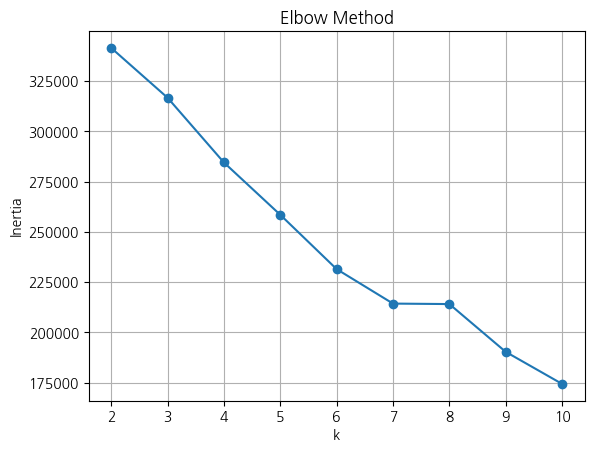

In [ ]:
# 엘보우 메서드로 적절한 군집 수 찾기
inertia = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(pca_data)
    inertia.append(kmeans.inertia_)

# 엘보우 그래프 시각화
plt.plot(k_range, inertia, marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(True)
plt.show()

In [ ]:
# 클러스터링 수행
kmeans = KMeans(n_clusters=7, random_state=42, n_init='auto')
cluster_labels = kmeans.fit_predict(pca_data)

# 결과를 final_data에 추가
final_data['cluster'] = cluster_labels

In [ ]:
cluster_summary = final_data.groupby('cluster').mean(numeric_only=True)
print(cluster_summary.T)

cluster                0              1              2              3  \
총여행횟수           1.029712       1.020210       1.023703       1.000000   
선택이유1           5.205987       5.356737       5.991055       5.480303   
선택이유2           5.801552       5.587425       5.734347       5.866667   
동반자 수           3.729047       3.385329       2.098837       4.343939   
15세 미만 수        1.103769       0.002545       0.000000       0.465152   
동반_배우자          0.967184       0.057784       0.000000       0.545455   
동반_자녀           0.956984       0.000749       0.000894       0.446970   
동반_부모           0.018182       0.000000       0.000447       0.080303   
동반_형제자매         0.008204       0.000299       0.000000       0.122727   
동반_친구           0.007982       0.923653       0.038909       0.300000   
동반_연인           0.000000       0.000299       0.894902       0.046970   
동반_친목단체         0.000665       0.000000       0.000000       0.030303   
반려동물            0.045898       0.012126       0.016

- 더미변수이므로 mean이 비율임

- Cluster 0: 가족 중심, 고소득층 휴양
  - 동반자 수 많고 자녀 포함 (자녀 동반 96%)
  - 숙박·음식·교통비 모두 높음
  - 주 활동: 자연(41%), 휴양(17%)
  - 평균 연령 중상 (약 4점대), 소득 높음 (5.8)
  > 📌 타깃: 가족 단위 고소득층 / 웰니스·휴양 중심 프로그램 적합

- Cluster 1: 친구/혼자 여행, 2030 세대
  - 친구 동반 비율 매우 높음 (92%), 연인·자녀 거의 없음
  - 지출은 중간, 쇼핑·음식 중심
  - 주 활동: 자연(49%), 음식(13%), 체험(11%)
  - 연령 상대적으로 젊고(3.7), 소득 보통
  > 📌 타깃: 친구와의 여가, 청년층 자유여행자 / SNS용 웰니스 체험 가능

- Cluster 2: 연인 중심 커플 여행
  - 연인 동반 비율 매우 높음 (89%)
  - 소수의 체험/자연/음식 활동
  - 소비는 평균보다 약간 낮음
  - 연령 낮고(2.7), 소득도 낮은 편
  > 📌 타깃: 연인 대상 프라이빗 웰니스, 감성여행 콘텐츠 / 뷰 좋은 숙소+스파

- Cluster 3: 가족 중심 중장년층, 고소비
  - 배우자,자녀 동반 많고, 전체 소비 압도적
  - 음식점비, 숙박비, 교통비 등 최고 수준
  - 활동: 자연(49%), 휴양(21%)
  - 연령 높음, 소득 높음
  > 📌 타깃: 럭셔리 가족형 웰니스 코스 / 온천, 힐링 리조트 등

- Cluster 4: 단체(친목/모임) 여행객
  - 동반자 수 매우 많음 (평균 14.6명)
  - 친목단체 97%
  - 소비는 중간 정도
  - 활동: 자연(47%), 음식(13%)
  = 연령 높음(5.3), 소득 보통
  > 📌 타깃: 기업 워케이션, 단체 웰니스 프로그램 / 템플스테이, 산림치유 등

- Cluster 5: 효도여행, 문화+방문 중심, 자매/모녀 여행일 가능성도!
  - 형제자매/부모 동반 비율 매우 높음 + 평균 3-40대
  - 활동: 방문(26%), 문화/역사(7%), 자연(33%) 차분한 활동 선호
  - 연령 중간, 소득 높음
  - 소비: 음식과 교통 지출 높음
  > 📌 타깃: 여성 대상 웰니스+문화 복합 코스 / 미술관+찜질방, 전통체험 등

- Cluster 6: 시니어/부부 중심, 저소비형
  - 배우자 동반 높음 (78%), 자녀/친구 없음
  - 활동: 방문(23%), 자연(36%), 휴양(15%)
  - 쇼핑/레저 소비 낮음
  - 연령 높음, 소득 보통 이하
  > 📌 타깃: 실버 웰니스 코스 / 걷기, 숲길, 온천 등 조용한 휴양에 적합

| 클러스터 | 타깃         | 상품 아이디어                                      |
| ---- | ---------- | -------------------------------------------- |
| 0    | 고소득 가족     | ‘**온 가족 힐링 숲캉스**’ : 키즈+부모 위한 자연 테마파크 + 스파    |
| 1    | 2030 친구/혼자 | ‘**혼자 떠나는 감성 회복 여행**’ : 혼캉스+요가+사진 명소         |
| 2    | 연인         | ‘**커플 프라이빗 힐링 패키지**’ : 뷰 좋은 숙소+별보기+스파        |
| 3    | 고소비 가족     | ‘**프리미엄 힐링 리조트 투어**’ : VIP 자연 리조트 + 미슐랭 식사   |
| 4    | 단체 여행      | ‘**웰니스 워케이션 리트릿**’ : 명상, 단체 요가, 산림치유, 팀빌딩    |
| 5    | 중년 여성      | ‘**모녀 미술·찜질 투어**’ : 미술관+전통 찜질방+한방차 체험        |
| 6    | 시니어 부부     | ‘**시니어 웰니스 산책 여행**’ : 걷기 좋은 숲길 + 온천 + 숙면 클래스 |


In [ ]:
# 군집별 인원 수
cluster_counts = final_data['cluster'].value_counts()
print(cluster_counts)

cluster
6    6795
1    6680
0    4510
2    2236
5    2017
4     965
3     660
Name: count, dtype: int64


# 지역선정

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/BDA/국내여행조사_데이터/2024_국내_관광객만.csv')
df

,ID,SA1_1,SA1_2,SA1_3,SA1_4,SA1_5,MON_EXP_1,MON_EXP_2,MON_EXP_3,MON_EXP_4,...,국내_여행방문지_국내당일1,국내_여행방문지_국내당일2,국내_여행방문지_관광전체1,국내_여행방문지_관광전체2,국내_여행방문지_관광숙박1,국내_여행방문지_관광숙박2,국내_여행방문지_관광당일1,국내_여행방문지_관광당일2,국내_여행방문지_기타전체1,국내_여행방문지_기타전체2
0,11010550271_275003,1,0,0,0,0,1,2,2,2,...,NaN,NaN,10.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN
1,11010550271_275004,1,0,0,0,0,1,2,2,2,...,NaN,NaN,10.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN
2,11010550271_275011,1,0,0,0,0,1,2,2,2,...,NaN,NaN,16.0,NaN,16.0,NaN,NaN,NaN,NaN,NaN
3,11010680011_420482,1,0,0,0,0,1,2,2,2,...,9.0,NaN,9.0,NaN,NaN,NaN,9.0,NaN,NaN,NaN
4,11010680011_420489,1,0,0,0,0,1,2,2,2,...,12.0,NaN,12.0,NaN,NaN,NaN,12.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23858,39020611051_690356,1,0,0,0,0,1,2,2,2,...,NaN,NaN,16.0,NaN,16.0,NaN,NaN,NaN,NaN,NaN
23859,39020611051_690403,1,0,0,0,0,1,2,2,2,...,17.0,NaN,17.0,NaN,NaN,NaN,17.0,NaN,NaN,NaN
23860,39020611051_690406,1,0,0,0,0,1,2,2,2,...,NaN,NaN,9.0,NaN,9.0,NaN,NaN,NaN,NaN,NaN
23861,39020611051_690417,1,0,0,0,0,1,2,2,2,...,17.0,NaN,17.0,NaN,NaN,NaN,17.0,NaN,NaN,NaN


### 데이터 확인

In [ ]:
df['국내_여행방문지_국내전체1'].isnull().sum()

np.int64(0)

In [ ]:
df['국내_여행방문지_국내전체2'].isnull().sum()

np.int64(22451)

In [ ]:
df['국내_여행방문지_관광전체2'].isnull().sum()

np.int64(22742)

In [ ]:
((df['국내_여행방문지_관광전체1'].isnull()) & (df['국내_여행방문지_관광전체2'].isnull())).sum()

np.int64(6)

In [ ]:
df.iloc[:,-14:]

,국내_여행방문지_국내전체1,국내_여행방문지_국내전체2,국내_여행방문지_국내숙박1,국내_여행방문지_국내숙박2,국내_여행방문지_국내당일1,국내_여행방문지_국내당일2,국내_여행방문지_관광전체1,국내_여행방문지_관광전체2,국내_여행방문지_관광숙박1,국내_여행방문지_관광숙박2,국내_여행방문지_관광당일1,국내_여행방문지_관광당일2,국내_여행방문지_기타전체1,국내_여행방문지_기타전체2
0,10.0,NaN,10.0,NaN,NaN,NaN,10.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN
1,10.0,NaN,10.0,NaN,NaN,NaN,10.0,NaN,10.0,NaN,NaN,NaN,NaN,NaN
2,16.0,NaN,16.0,NaN,NaN,NaN,16.0,NaN,16.0,NaN,NaN,NaN,NaN,NaN
3,9.0,NaN,NaN,NaN,9.0,NaN,9.0,NaN,NaN,NaN,9.0,NaN,NaN,NaN
4,12.0,NaN,NaN,NaN,12.0,NaN,12.0,NaN,NaN,NaN,12.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23858,16.0,NaN,16.0,NaN,NaN,NaN,16.0,NaN,16.0,NaN,NaN,NaN,NaN,NaN
23859,17.0,NaN,NaN,NaN,17.0,NaN,17.0,NaN,NaN,NaN,17.0,NaN,NaN,NaN
23860,9.0,NaN,9.0,NaN,NaN,NaN,9.0,NaN,9.0,NaN,NaN,NaN,NaN,NaN
23861,17.0,NaN,NaN,NaN,17.0,NaN,17.0,NaN,NaN,NaN,17.0,NaN,NaN,NaN


In [ ]:
df[((df['국내_여행방문지_관광전체1'].isnull()) & (df['국내_여행방문지_관광전체2'].isnull()))].iloc[:,-14:]

,국내_여행방문지_국내전체1,국내_여행방문지_국내전체2,국내_여행방문지_국내숙박1,국내_여행방문지_국내숙박2,국내_여행방문지_국내당일1,국내_여행방문지_국내당일2,국내_여행방문지_관광전체1,국내_여행방문지_관광전체2,국내_여행방문지_관광숙박1,국내_여행방문지_관광숙박2,국내_여행방문지_관광당일1,국내_여행방문지_관광당일2,국내_여행방문지_기타전체1,국내_여행방문지_기타전체2
856,9.0,9.0,NaN,NaN,9.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0
2125,12.0,9.0,NaN,NaN,12.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,12.0,9.0
4436,15.0,15.0,NaN,NaN,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,15.0,15.0
10520,4.0,1.0,NaN,NaN,4.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0
12559,4.0,9.0,4.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,9.0
21381,9.0,12.0,NaN,NaN,9.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,9.0,12.0


In [ ]:
df[((df['국내_여행방문지_관광전체1'].isnull()) & (df['국내_여행방문지_관광전체2'].isnull()))].iloc[:,:6]

,ID,SA1_1,SA1_2,SA1_3,SA1_4,SA1_5
856,1111074029A_471622,1,0,0,0,2
2125,11230641651_473003,1,0,2,0,0
4436,22060640481_450272,1,0,0,0,4
10520,3105088502A_456283,1,0,1,0,1
12559,3120058390A_606676,1,0,2,0,0
21381,3710053059A_492325,1,0,0,0,3


### 지역별 만족도 정리

만족도를 보면 관광지가 아닌 전체 여행지에 대한 만족 설문임. 그리고 우리는 지역 별 여행 만족도(여기선 친지 방문+출장도 포함)와 서비스를 확인하는게 목적이니까, 관광 방문지가 아닌 여행방문지를 확인함

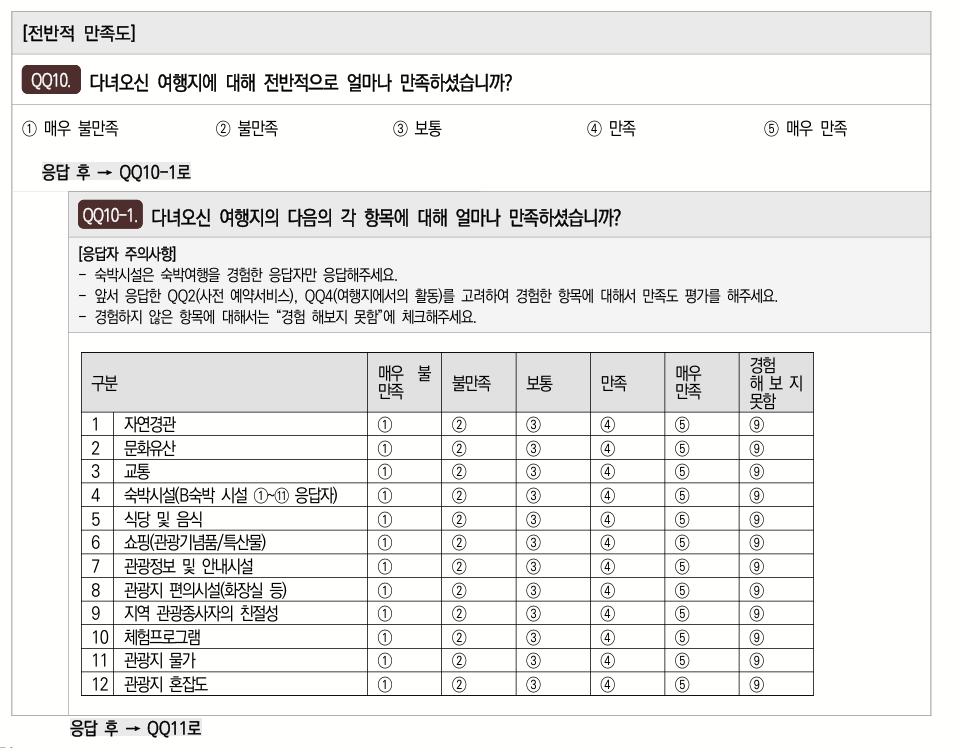

In [ ]:
df['국내_여행방문지_국내전체1'].isnull().sum()

np.int64(0)

In [ ]:
(~df['국내_여행방문지_국내전체2'].isnull()).sum()

np.int64(1412)

In [ ]:
df['A9'].isnull().sum()

np.int64(0)

In [ ]:
df['A9A_9'].isnull().sum()

np.int64(0)

In [ ]:
df['A9'].value_counts()

,count
A9,
4.0,17396
5.0,5953
3.0,495
2.0,16
1.0,3


In [ ]:
df_1 = df[['ID','국내_여행방문지_국내전체1', '국내_여행방문지_국내전체2',
          'A9','A9A_1', 'A9A_2','A9A_3','A9A_4','A9A_5','A9A_6','A9A_7','A9A_8','A9A_9','A9A_10','A9A_11','A9A_12','A10', 'A11']]

df_1.head()

,ID,국내_여행방문지_국내전체1,국내_여행방문지_국내전체2,A9,A9A_1,A9A_2,A9A_3,A9A_4,A9A_5,A9A_6,A9A_7,A9A_8,A9A_9,A9A_10,A9A_11,A9A_12,A10,A11
0,11010550271_275003,10.0,NaN,4.0,5.0,4.0,4.0,4.0,5.0,4.0,4.0,4.0,4.0,9.0,3.0,4.0,4.0,4.0
1,11010550271_275004,10.0,NaN,4.0,4.0,5.0,4.0,4.0,4.0,5.0,4.0,4.0,4.0,9.0,4.0,4.0,4.0,4.0
2,11010550271_275011,16.0,NaN,4.0,4.0,4.0,3.0,4.0,4.0,3.0,4.0,4.0,4.0,9.0,3.0,4.0,4.0,4.0
3,11010680011_420482,9.0,NaN,4.0,4.0,9.0,4.0,NaN,3.0,9.0,4.0,4.0,4.0,4.0,3.0,4.0,4.0,3.0
4,11010680011_420489,12.0,NaN,4.0,4.0,9.0,4.0,NaN,3.0,9.0,4.0,4.0,3.0,4.0,4.0,4.0,4.0,4.0


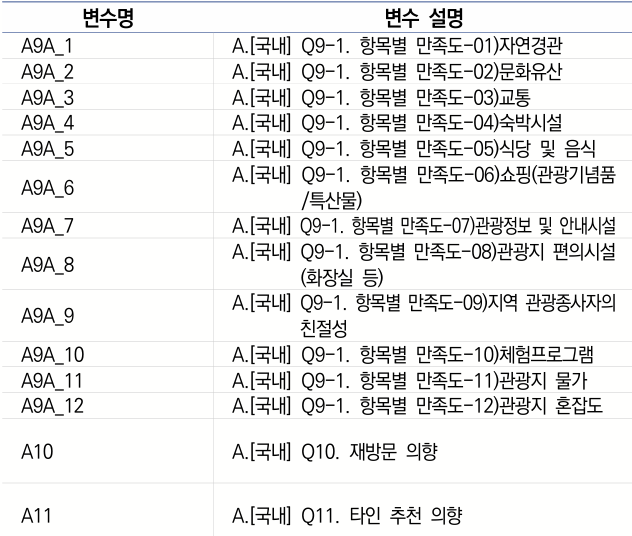

- 숙박시설 만족도 항목만 null값이 많음(숙박X사람들 체크X) --> 지역보다는 그 숙박시설의 문제일듯
- 나머지는 지역의 만족도와 다 연관있어보임. 일단 냅두기

In [ ]:
df_1.isnull().sum()

,0
ID,0
국내_여행방문지_국내전체1,0
국내_여행방문지_국내전체2,22451
A9,0
A9A_1,0
A9A_2,0
A9A_3,0
A9A_4,16683
A9A_5,0
A9A_6,0


In [ ]:
df_1 = df_1.drop(columns='A9A_4')

In [ ]:
df_1

,ID,국내_여행방문지_국내전체1,국내_여행방문지_국내전체2,A9,A9A_1,A9A_2,A9A_3,A9A_5,A9A_6,A9A_7,A9A_8,A9A_9,A9A_10,A9A_11,A9A_12,A10,A11
0,11010550271_275003,10.0,NaN,4.0,5.0,4.0,4.0,5.0,4.0,4.0,4.0,4.0,9.0,3.0,4.0,4.0,4.0
1,11010550271_275004,10.0,NaN,4.0,4.0,5.0,4.0,4.0,5.0,4.0,4.0,4.0,9.0,4.0,4.0,4.0,4.0
2,11010550271_275011,16.0,NaN,4.0,4.0,4.0,3.0,4.0,3.0,4.0,4.0,4.0,9.0,3.0,4.0,4.0,4.0
3,11010680011_420482,9.0,NaN,4.0,4.0,9.0,4.0,3.0,9.0,4.0,4.0,4.0,4.0,3.0,4.0,4.0,3.0
4,11010680011_420489,12.0,NaN,4.0,4.0,9.0,4.0,3.0,9.0,4.0,4.0,3.0,4.0,4.0,4.0,4.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23858,39020611051_690356,16.0,NaN,5.0,3.0,3.0,4.0,5.0,4.0,3.0,3.0,4.0,3.0,4.0,4.0,5.0,5.0
23859,39020611051_690403,17.0,NaN,4.0,4.0,4.0,4.0,4.0,9.0,4.0,4.0,3.0,9.0,3.0,4.0,4.0,3.0
23860,39020611051_690406,9.0,NaN,4.0,4.0,3.0,4.0,4.0,9.0,4.0,4.0,4.0,9.0,4.0,4.0,4.0,4.0
23861,39020611051_690417,17.0,NaN,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,9.0,4.0,4.0,4.0,4.0


In [ ]:
cols = ['국내_여행방문지_국내전체1', '국내_여행방문지_국내전체2', 'A9', 'A10', 'A11']
# 지역1 그룹핑
region1 = df.dropna(subset=['국내_여행방문지_국내전체1']) \
            .groupby('국내_여행방문지_국내전체1')[['A9','A10','A11','A9A_1','A9A_2','A9A_3','A9A_5','A9A_6','A9A_7','A9A_8','A9A_9','A9A_10','A9A_11','A9A_12']] \
            .mean() \
            .rename(columns=lambda x: x + '_1')

# 지역2 그룹핑
region2 = df.dropna(subset=['국내_여행방문지_국내전체2']) \
            .groupby('국내_여행방문지_국내전체2')[['A9', 'A10', 'A11','A9A_1','A9A_2','A9A_3','A9A_5','A9A_6','A9A_7','A9A_8','A9A_9','A9A_10','A9A_11','A9A_12']] \
            .mean() \
            .rename(columns=lambda x: x + '_2')

# 두 결과를 지역번호 기준으로 병합 (outer join)
merged = pd.merge(region1, region2, left_index=True, right_index=True, how='outer')

merged = merged.sort_index()
print(merged)

                    A9_1     A10_1     A11_1   A9A_1_1   A9A_2_1   A9A_3_1  \
국내_여행방문지_국내전체1                                                               
1.0             4.170758  3.987193  3.914621  4.972252  6.088581  4.043757   
2.0             4.212171  4.085526  4.013980  4.643092  5.797697  4.106908   
3.0             4.123762  4.044554  3.950495  5.027228  6.292079  4.136139   
4.0             4.130645  4.000000  3.967742  4.575806  6.085484  4.164516   
5.0             4.285714  4.208791  4.076923  4.620879  5.093407  4.379121   
6.0             4.121212  3.969697  3.838384  4.603535  6.287879  4.194444   
7.0             4.227778  4.097222  4.022222  4.644444  5.875000  4.225000   
8.0             4.122449  3.925170  3.802721  4.557823  5.639456  4.238095   
9.0             4.169486  4.028914  3.966164  4.614888  6.231313  4.202707   
10.0            4.218135  4.066724  4.000428  4.618477  5.969632  4.234816   
11.0            4.172291  3.996448  3.930728  4.565719  5.535524

In [ ]:
# 지역 당 모두 평균
merged['A9_avg'] = merged[['A9_1', 'A9_2']].mean(axis=1)
merged['A10_avg'] = merged[['A10_1', 'A10_2']].mean(axis=1)
merged['A11_avg'] = merged[['A11_1', 'A11_2']].mean(axis=1)
merged['A9A_1_avg'] = merged[['A9A_1_1', 'A9A_1_2']].mean(axis=1)
merged['A9A_2_avg'] = merged[['A9A_2_1', 'A9A_2_2']].mean(axis=1)
merged['A9A_3_avg'] = merged[['A9A_3_1', 'A9A_3_2']].mean(axis=1)
merged['A9A_5_avg'] = merged[['A9A_5_1', 'A9A_5_2']].mean(axis=1)
merged['A9A_6_avg'] = merged[['A9A_6_1', 'A9A_6_2']].mean(axis=1)
merged['A9A_7_avg'] = merged[['A9A_7_1', 'A9A_7_2']].mean(axis=1)
merged['A9A_8_avg'] = merged[['A9A_8_1', 'A9A_8_2']].mean(axis=1)
merged['A9A_9_avg'] = merged[['A9A_9_1', 'A9A_9_2']].mean(axis=1)
merged['A9A_10_avg'] = merged[['A9A_10_1', 'A9A_10_2']].mean(axis=1)
merged['A9A_11_avg'] = merged[['A9A_11_1', 'A9A_11_2']].mean(axis=1)
merged['A9A_12_avg'] = merged[['A9A_12_1', 'A9A_12_2']].mean(axis=1)

# 기존 _1, _2 컬럼 삭제
merged.drop(columns=[
    'A9_1', 'A9_2',
    'A10_1', 'A10_2',
    'A11_1', 'A11_2',
    'A9A_1_1', 'A9A_1_2',
    'A9A_2_1', 'A9A_2_2',
    'A9A_3_1', 'A9A_3_2',
    'A9A_5_1', 'A9A_5_2',
    'A9A_6_1', 'A9A_6_2',
    'A9A_7_1', 'A9A_7_2',
    'A9A_8_1', 'A9A_8_2',
    'A9A_9_1', 'A9A_9_2',
    'A9A_10_1', 'A9A_10_2',
    'A9A_11_1', 'A9A_11_2',
    'A9A_12_1', 'A9A_12_2'
], inplace=True)

print(merged)

                  A9_avg   A10_avg   A11_avg  A9A_1_avg  A9A_2_avg  A9A_3_avg  \
국내_여행방문지_국내전체1                                                                  
1.0             4.160851  4.003031  3.957311   4.863484   6.015988   3.965275   
2.0             4.241006  4.122128  4.078419   4.599324   6.121071   4.101073   
3.0             4.091293  4.036983  3.960542   4.763614   6.013687   4.126893   
4.0             4.225323  4.020000  4.043871   4.407903   6.262742   4.142258   
5.0             4.242857  4.154396  4.088462   4.585440   5.271703   4.389560   
6.0             4.050402  3.923624  3.827355   4.720135   6.297001   4.117630   
7.0             4.242921  4.113127  4.011111   4.628674   5.614919   4.306048   
8.0             4.149460  3.874350  3.813125   4.514206   5.555022   4.266106   
9.0             4.182243  4.024457  3.958082   4.619944   6.520657   4.128853   
10.0            4.252685  4.070596  3.994895   4.665622   6.213539   4.159961   
11.0            4.132198  3.

In [ ]:
region_map = {
    1: '서울', 2: '부산', 3: '대구', 4: '인천', 5: '광주',
    6: '대전', 7: '울산', 8: '세종', 9: '경기', 10: '강원',
    11: '충북', 12: '충남', 13: '전북', 14: '전남',
    15: '경북', 16: '경남', 17: '제주'
}
# 인덱스를 지역명으로 매핑
merged_named = merged.rename(index=region_map)
print(merged_named)

                  A9_avg   A10_avg   A11_avg  A9A_1_avg  A9A_2_avg  A9A_3_avg  \
국내_여행방문지_국내전체1                                                                  
서울              4.160851  4.003031  3.957311   4.863484   6.015988   3.965275   
부산              4.241006  4.122128  4.078419   4.599324   6.121071   4.101073   
대구              4.091293  4.036983  3.960542   4.763614   6.013687   4.126893   
인천              4.225323  4.020000  4.043871   4.407903   6.262742   4.142258   
광주              4.242857  4.154396  4.088462   4.585440   5.271703   4.389560   
대전              4.050402  3.923624  3.827355   4.720135   6.297001   4.117630   
울산              4.242921  4.113127  4.011111   4.628674   5.614919   4.306048   
세종              4.149460  3.874350  3.813125   4.514206   5.555022   4.266106   
경기              4.182243  4.024457  3.958082   4.619944   6.520657   4.128853   
강원              4.252685  4.070596  3.994895   4.665622   6.213539   4.159961   
충북              4.132198  3.

In [ ]:
merged_named.index.name = '국내_여행방문지'

In [ ]:
# A9 기준
merged_named = merged_named.sort_values(by='A9_avg', ascending=False)
print(merged_named)

            A9_avg   A10_avg   A11_avg  A9A_1_avg  A9A_2_avg  A9A_3_avg  \
국내_여행방문지                                                                  
전남        4.329509  4.246056  4.137112   4.728057   5.243006   4.336253   
전북        4.312062  4.209288  4.057748   4.697962   5.294482   4.227049   
제주        4.294287  4.130732  4.124706   4.835520   5.085267   4.118007   
경남        4.263853  4.148731  4.051487   4.631640   5.414575   4.175907   
강원        4.252685  4.070596  3.994895   4.665622   6.213539   4.159961   
울산        4.242921  4.113127  4.011111   4.628674   5.614919   4.306048   
광주        4.242857  4.154396  4.088462   4.585440   5.271703   4.389560   
부산        4.241006  4.122128  4.078419   4.599324   6.121071   4.101073   
인천        4.225323  4.020000  4.043871   4.407903   6.262742   4.142258   
충남        4.197495  4.016515  3.917690   4.562869   5.784120   4.136670   
경북        4.188641  4.052820  4.007201   4.677620   5.745143   4.221168   
경기        4.182243  4.024

In [ ]:
# A10 기준
merged_named = merged_named.sort_values(by='A10_avg', ascending=False)
print(merged_named)

            A9_avg   A10_avg   A11_avg  A9A_1_avg  A9A_2_avg  A9A_3_avg  \
국내_여행방문지                                                                  
전남        4.329509  4.246056  4.137112   4.728057   5.243006   4.336253   
전북        4.312062  4.209288  4.057748   4.697962   5.294482   4.227049   
광주        4.242857  4.154396  4.088462   4.585440   5.271703   4.389560   
경남        4.263853  4.148731  4.051487   4.631640   5.414575   4.175907   
제주        4.294287  4.130732  4.124706   4.835520   5.085267   4.118007   
부산        4.241006  4.122128  4.078419   4.599324   6.121071   4.101073   
울산        4.242921  4.113127  4.011111   4.628674   5.614919   4.306048   
강원        4.252685  4.070596  3.994895   4.665622   6.213539   4.159961   
경북        4.188641  4.052820  4.007201   4.677620   5.745143   4.221168   
대구        4.091293  4.036983  3.960542   4.763614   6.013687   4.126893   
경기        4.182243  4.024457  3.958082   4.619944   6.520657   4.128853   
인천        4.225323  4.020

In [ ]:
# A11 기준
merged_named = merged_named.sort_values(by='A11_avg', ascending=False)
print(merged_named)

            A9_avg   A10_avg   A11_avg  A9A_1_avg  A9A_2_avg  A9A_3_avg  \
국내_여행방문지                                                                  
전남        4.329509  4.246056  4.137112   4.728057   5.243006   4.336253   
제주        4.294287  4.130732  4.124706   4.835520   5.085267   4.118007   
광주        4.242857  4.154396  4.088462   4.585440   5.271703   4.389560   
부산        4.241006  4.122128  4.078419   4.599324   6.121071   4.101073   
전북        4.312062  4.209288  4.057748   4.697962   5.294482   4.227049   
경남        4.263853  4.148731  4.051487   4.631640   5.414575   4.175907   
인천        4.225323  4.020000  4.043871   4.407903   6.262742   4.142258   
울산        4.242921  4.113127  4.011111   4.628674   5.614919   4.306048   
경북        4.188641  4.052820  4.007201   4.677620   5.745143   4.221168   
강원        4.252685  4.070596  3.994895   4.665622   6.213539   4.159961   
대구        4.091293  4.036983  3.960542   4.763614   6.013687   4.126893   
경기        4.182243  4.024

### 만족도 정렬 결과

- A9 전반적 만족도: **전남**, **전북**, 제주, **경남**, 강원
- A10 재방문 의향: **전남**, **전북**, **광주**, **경남**, 제주
- A11 타인추천 의향: **전남**, 제주, **광주**, 부산, **전북**
- A9A_9 지역관광종사자의 친절성: **광주**, 대전, **전남**, **경남**, **전북**

- 약간의 한계: 이상치를 살펴보진 않음..중앙값으로 해봤는데 소용X, 대부분이 비슷함


In [ ]:
# A9A_9  기준
merged_named = merged_named.sort_values(by='A9A_9_avg', ascending=False)
print(merged_named)

            A9_avg   A10_avg   A11_avg  A9A_1_avg  A9A_2_avg  A9A_3_avg  \
국내_여행방문지                                                                  
광주        4.242857  4.154396  4.088462   4.585440   5.271703   4.389560   
대전        4.050402  3.923624  3.827355   4.720135   6.297001   4.117630   
전남        4.329509  4.246056  4.137112   4.728057   5.243006   4.336253   
경남        4.263853  4.148731  4.051487   4.631640   5.414575   4.175907   
전북        4.312062  4.209288  4.057748   4.697962   5.294482   4.227049   
울산        4.242921  4.113127  4.011111   4.628674   5.614919   4.306048   
세종        4.149460  3.874350  3.813125   4.514206   5.555022   4.266106   
경북        4.188641  4.052820  4.007201   4.677620   5.745143   4.221168   
서울        4.160851  4.003031  3.957311   4.863484   6.015988   3.965275   
부산        4.241006  4.122128  4.078419   4.599324   6.121071   4.101073   
인천        4.225323  4.020000  4.043871   4.407903   6.262742   4.142258   
제주        4.294287  4.130

In [ ]:
# 국내전체1 지역별 횟수
count_1 = df['국내_여행방문지_국내전체1'].value_counts().sort_index()

# 국내전체2 지역별 횟수
count_2 = df['국내_여행방문지_국내전체2'].value_counts().sort_index()

region_counts = pd.DataFrame({
    '국내전체1_횟수': count_1,
    '국내전체2_횟수': count_2
}).fillna(0).astype(int)

region_counts['합계'] = region_counts['국내전체1_횟수'] + region_counts['국내전체2_횟수']

In [ ]:
region_map = {
    1: '서울', 2: '부산', 3: '대구', 4: '인천', 5: '광주',
    6: '대전', 7: '울산', 8: '세종', 9: '경기', 10: '강원',
    11: '충북', 12: '충남', 13: '전북', 14: '전남',
    15: '경북', 16: '경남', 17: '제주'
}

region_counts.rename(index=region_map, inplace=True)
print(region_counts)

    국내전체1_횟수  국내전체2_횟수    합계
서울       937        53   990
부산      1216        63  1279
대구       404        34   438
인천       620        25   645
광주       182        20   202
대전       396        49   445
울산       360        31   391
세종       147        17   164
경기      3251       200  3451
강원      2338        94  2432
충북      1126        76  1202
충남      2348       137  2485
전북      1761       108  1869
전남      2903       185  3088
경북      2390       176  2566
경남      2493       126  2619
제주       991        18  1009


In [ ]:
region_counts.sort_values(by='합계', ascending=False)

,국내전체1_횟수,국내전체2_횟수,합계
경기,3251,200,3451
전남,2903,185,3088
경남,2493,126,2619
경북,2390,176,2566
충남,2348,137,2485
강원,2338,94,2432
전북,1761,108,1869
부산,1216,63,1279
충북,1126,76,1202
제주,991,18,1009


### 관광 활성화 지수 (23.06~24.05)

https://datalab.visitkorea.or.kr/datalab/portal/loc/getTourActivateForm.do#

- 전국평균 46.5 (지출 금액(현지인+외지인 관광지출) 핵심 요인, 관광 목적)으로 정리+핵심 방문자 및 성/연령, 숙박일수 등 확인 가능
- 전남 **평균 26.2, 중앙값 21.2** ✅
  - 강진군 16.8(여가서비스업 지출, 역사관광 관심도), 고흥군: 21.1(쇼핑업 지출, 자연관광 관심도), 곡성군: 16.3(여가 서비스업, 기타관광 관심), 광양시 28.5(숙박업 지출, 쇼핑 관심도), 구례군: 18.5(운송업 지출, 역사관광), 나주시: 30.3(여가서비스업, 레저스포츠), 담양군 29.4(여가서비스업, 자연관광), 목포시: 45.8(여행업, 기타관광), 무안군 25.6(여가서비스업, 자연관광), 보성군 18.9(여가서비스업, 체험관광), 순천시: 53(여가서비스업, 기타관광), 신안군 20(운송업, 자연관광), 여수시: 72.7(운송업, 숙박), 영광군: 19.3(여가서비스업, 기타관광), 영암군: 20.1(여가서비스업, 레저스포츠), 완도군: 18.5(여행업, 기타관광), 장성군 20.5(여가서비스업, 역사관광), 장흥군 15.8(여가서비스업, 자연관광), 진도군: 17.1(숙박업 지출, 자연관광), 함평군: 16.7(여가서비스업, 레저스포츠), 해남군: 21.3(여가서비스업, 역사관광), 화순군: 25.6(운송업, 체험관광)

- 전북 **평균 30.1, 중앙값: 24**
  - 고창군: 22.6, 군산시: 47.3, 김제시: 22.5, 남원시: 24, 무주군: 20.4, 부안군: 26.9, 순창군: 15.4, 완주군: 34.5, 익산시: 37.9, 임실군: 17, 장수: 13.3, 전주시 덕진구: 55.7, 전주시 완산구: 62.6, 정읍시: 24, 진안군: 15.9

- 광주 **평균 56.7, 중앙값:63.7**
  - 광산구: 67.3(현지인 방문, 쇼핑업, 기타관광), 남구: 33.4(외지인, 여행업, 음식관심도), 동구: 46.9(외지인, 여행업, 쇼핑관심도), 북구: 63.7(현지인, 여행업, 문화관광), 서구: 72(외지인, 쇼핑업, 기타관광)

- 경남 **평균 35.1, 중앙값: 32.65**
  - 거제시: 54.1, 거창군: 18.9, 고성군: 22.2, 김해시 75.9, 남해군: 25, 밀양시: 34.3, 사천시: 33.2, 산청군: 22.2, 양산시: 63.5, 의령군: 15.3, 진주시: 47.9, 창녕군: 23.9, 창원시 마산 합포구: 41.8, 창원시 마산 회원구: 33.2, 창원시 성산구: 48.7, 창원시 의창구: 49.1, 창원시 진해구: 32.1, 통영시: 39.3, 하동군: 20.5, 함안군: 20.9, 함양군 17.4, 합천: 20.7

# 시설 수 집계

**필요한 라이브러리 불러오기**

In [ ]:
import geopandas as gpd

# GeoJSON은 기본적으로 UTF-8 → encoding 생략
shapefile_path = "/content/drive/MyDrive/BDA/외부데이터-시설/행정동.geojson"
dong_gdf = gpd.read_file(shapefile_path)
dong_gdf = dong_gdf[dong_gdf['sidonm'].str.contains('전라남도')]
data = dong_gdf[['sggnm']].drop_duplicates().sort_values(by='sggnm').reset_index(drop=True)

## 1.치유의숲

In [ ]:
import pandas as pd
치유의숲 = pd.read_csv('/content/drive/MyDrive/BDA/외부데이터-시설/1.산림청_치유의숲 현황.csv', encoding='cp949')
치유의숲.head()

,연번,지역,시설명,주소,전화번호,홈페이지,참여방법,관리주체
0,1,경기도,산음 치유의숲,경기도 양평군 단월면 고북길 347,031-774-7687,https://cafe.naver.com/saneumhealing,전화/홈페이지,국립
1,2,경기도,국립양평치유의숲,경기도 양평군 양동면 황거길 262-10,031-8079-7950,http://www.fowi.or.kr,전화/홈페이지,국립
2,3,경기도,잣향기 푸른숲,경기도 가평군 상면 축령로 289-146,031-8008-6769,http://farm.gg.go.kr/sigt/89,전화/홈페이지,공립
3,4,경기도,하늘아래 치유의숲,경기도 포천시 신북면 금동리 산39,031-538-3337,https://www.pocheon.go.kr/ktour/contents.do?ke...,전화/홈페이지,공립
4,5,경기도,용문산 치유의숲,경기도 양평군 양평읍 백안리 산 68-5,070-8811-1008,http://www.swijapark.com,전화/홈페이지,공립


In [ ]:
치유의숲 = 치유의숲[치유의숲['지역']=='전라도']

In [ ]:
치유의숲.head()

,연번,지역,시설명,주소,전화번호,홈페이지,참여방법,관리주체
20,21,전라도,장성 치유의 숲,전남 장성군 서삼면 추암로 716,061-393-1777,http://jangseong.fowi.or.kr,전화/홈페이지,국립
21,22,전라도,곡성치유의숲,전남 곡성군 곡성읍 청계동로 519,061-363-0901,http://www.fowi.or.kr,전화/홈페이지,국립
22,23,전라도,장흥편백 치유의 숲,전남 장흥군 장흥읍 우산리 산 20-26,061-864-3265,https://www.jhwoodland.co.kr/subpage/?site=woo...,전화/홈페이지,공립
23,24,전라도,만연산치유의숲,전남 화순군 화순읍 동구리 181-3번지,061-379-5896,https://forest.hwasun.go.kr/contents.do?S=S01&...,전화/홈페이지,공립
24,25,전라도,빛가람치유의숲,전남 나주시 산포면 산제리 542-6,061-338-4255,https://jnforest.jeonnam.go.kr/content/view.do...,전화/홈페이지,공립


In [ ]:
치유의숲[['lon', 'lat']] = 치유의숲['주소'].progress_apply(get_coords_kakao)

100%|██████████| 8/8 [00:04<00:00,  1.73it/s]


In [ ]:
치유의숲['시군구'] = 치유의숲.progress_apply(
    lambda row: find_adm_nm(dong_gdf, row['lon'], row['lat']), axis=1)

100%|██████████| 8/8 [00:00<00:00, 792.24it/s]


In [ ]:
data['치유의숲'] = 0

for idx, row in data.iterrows():
    name = row['sggnm']
    count = 치유의숲['시군구'].apply(lambda x: name in str(x)).sum()
    data.at[idx, '치유의숲'] = count

In [ ]:
data.head()

,sggnm,치유의숲
0,강진군,0
1,고흥군,1
2,곡성군,1
3,광양시,1
4,구례군,0


## 2.생태경관

In [ ]:
import pandas as pd
생태경관 = pd.read_csv('/content/drive/MyDrive/BDA/외부데이터-시설/2.전라남도_생태경관 보전지역 지정 현황.csv', encoding='cp949')
생태경관.head()

,지역명,위치,면적_제곱킬로미터,특징,지정일자,비고
0,지리산,전남 구례군 산동면 심원 계곡 및 토지면 피아골 일원,20.200,극상원시림(구상나무 등),1989-12-29,환경부 관리
1,섬진강 수달서식지,"전남 구례군 문척면, 간전면, 토지면 일원",1.834,수달 서식지,2001-12-01,환경부 관리
2,고산봉 붉은박쥐서식지,전남 함평군 대동면 일원,8.780,붉은박쥐 서식지,2002-05-01,환경부 관리
3,거금도 적대봉,전남 고흥군 거금도 적대봉 일원,8.365,멸종위기종과 특정 야생동식물 서식,2011-01-07,환경부 관리
4,광양백운산,"전남 광양시 옥룡면, 진사면, 다압면 일원",9.740,자연경관 수려 및 원시자연림,1993-04-26,전라남도 관리


In [ ]:
# '지역명' 또는 '위치' 기준으로 수동 매핑
mapping = {
    '지리산': '구례군',
    '섬진강 수달서식지': '구례군',
    '고산봉 붉은박쥐서식지': '함평군',
    '거금도 적대봉': '고흥군',
    '광양백운산': '광양시'
}

# 매핑 적용
생태경관['시군구'] = 생태경관['지역명'].map(mapping)

In [ ]:
생태경관['시군구']

,시군구
0,구례군
1,구례군
2,함평군
3,고흥군
4,광양시


In [ ]:
data['생태경관'] = 0

for idx, row in data.iterrows():
    name = row['sggnm']
    count = 생태경관['시군구'].apply(lambda x: name in str(x)).sum()
    data.at[idx, '생태경관'] = count

In [ ]:
data.head()

,sggnm,치유의숲,생태경관
0,강진군,0,0
1,고흥군,1,1
2,곡성군,1,0
3,광양시,1,1
4,구례군,0,2


## 3.탬플스테이

In [ ]:
import pandas as pd
템플스테이 = pd.read_csv('/content/drive/MyDrive/BDA/외부데이터-시설/3.전라남도_템플스테이 운영 사찰 현황.csv', encoding='cp949')
템플스테이.head()

,시군명,사찰명,주소
0,여수시,흥국사,전라남도 여수시 흥국사길 160
1,순천시,선암사,전라남도 순천시 승주읍 선암사길 450
2,순천시,송광사,전라남도 순천시 송광면 송광사안길 100
3,순천시,정혜사,전라남도 순천시 서면 정혜사길 32
4,구례군,연곡사,전라남도 구례군 토지면 피아골로 774


In [ ]:
템플스테이[['lon', 'lat']] =템플스테이['주소'].progress_apply(get_coords_kakao)

100%|██████████| 21/21 [00:11<00:00,  1.75it/s]


In [ ]:
템플스테이['시군구'] = 템플스테이.progress_apply(
    lambda row: find_adm_nm(dong_gdf, row['lon'], row['lat']), axis=1)

100%|██████████| 21/21 [00:00<00:00, 1018.81it/s]


In [ ]:
data['템플스테이'] = 0

for idx, row in data.iterrows():
    name = row['sggnm']
    count = 템플스테이['시군구'].apply(lambda x: name in str(x)).sum()
    data.at[idx, '템플스테이'] = count

In [ ]:
data.head()

,sggnm,치유의숲,생태경관,템플스테이
0,강진군,0,0,2
1,고흥군,1,1,1
2,곡성군,1,0,1
3,광양시,1,1,0
4,구례군,0,2,3


## 4.피부미용업

In [ ]:
import pandas as pd
피부미용업 = pd.read_csv('/content/drive/MyDrive/BDA/외부데이터-시설/4.전라남도_피부미용업 현황 정보.csv', encoding='cp949')
피부미용업.head()

,업소명,업종,업태,지번주소(자치단체제외),도로명주소(자치단체제외)
0,플로라스킨앤바디,피부미용업,피부미용업,목포시 산정동 1202번지 상가 신안비치아파트-201,"목포시 청호로 209, (산정동)"
1,미즈스킨케어,피부미용업,피부미용업,목포시 옥암동 959번지 6호 (1층),"목포시 백년대로375번길 29, (옥암동,(1층))"
2,최홍희피부샵,피부미용업,피부미용업,목포시 상동 1002번지 10호 3층,"목포시 옥암로 41, 3층 (상동)"
3,미소피부,피부미용업,피부미용업,목포시 상동 979번지 5호 2층,"목포시 교육로 30, (상동,2층)"
4,아베끄마린뷰티아카데미,피부미용업,피부미용업,목포시 옥암동 991번지 8호,"목포시 옥암로 72, (옥암동)"


In [ ]:
피부미용업[['lon', 'lat']] = 피부미용업['지번주소(자치단체제외)'].progress_apply(get_coords_kakao)

100%|██████████| 1105/1105 [10:30<00:00,  1.75it/s]


In [ ]:
피부미용업['시군구'] = 피부미용업.progress_apply(
    lambda row: find_adm_nm(dong_gdf, row['lon'], row['lat']), axis=1)

100%|██████████| 1105/1105 [00:00<00:00, 1309.34it/s]


In [ ]:
data['피부미용업'] = 0

for idx, row in data.iterrows():
    name = row['sggnm']
    count = 피부미용업['시군구'].apply(lambda x: name in str(x)).sum()
    data.at[idx, '피부미용업'] = count

In [ ]:
data.head()

,sggnm,치유의숲,생태경관,템플스테이,피부미용업
0,강진군,0,0,2,7
1,고흥군,1,1,1,6
2,곡성군,1,0,1,5
3,광양시,1,1,0,25
4,구례군,0,2,3,1


## 5.숙박시설

* https://datalab.visitkorea.or.kr/datalab/portal/bzm/getBzmanLodgForm.do# 에서 수동으로 매핑

* 0	강진군 : 39
* 1	고흥군 : 66
* 2	곡성군 : 23
* 3	광양시 : 107
* 4	구례군 : 65
* 5	나주시 : 59
* 6	담양군 : 79
* 7	목포시 : 306
* 8	무안군 : 70
* 9	보성군 : 44
* 10	순천시 : 251
* 11	신안군 : 72
* 12	여수시 : 573
* 13	영광군 : 49
* 14	영암군 : 65
* 15	완도군 : 125
* 16	장성군 : 29
* 17	장흥군 : 31
* 18	진도군 : 36
* 19	함평군 : 20
* 20	해남군 : 75
* 21	화순군 : 49


In [ ]:
# 시군구별 숙박시설 수 데이터
accom_data = {
    'sggnm': ['강진군', '고흥군', '곡성군', '광양시', '구례군', '나주시', '담양군', '목포시', '무안군', '보성군',
              '순천시', '신안군', '여수시', '영광군', '영암군', '완도군', '장성군', '장흥군', '진도군', '함평군',
              '해남군', '화순군'],
    '숙박시설': [39, 66, 23, 107, 65, 59, 79, 306, 70, 44,
              251, 72, 573, 49, 65, 125, 29, 31, 36, 20,
              75, 49]}

accom_df = pd.DataFrame(accom_data)
# 시군구 기준 병합
data = pd.merge(data, accom_df, on='sggnm', how='left')
data.head()

,sggnm,치유의숲,생태경관,템플스테이,피부미용업,숙박시설
0,강진군,0,0,2,7,39
1,고흥군,1,1,1,6,66
2,곡성군,1,0,1,5,23
3,광양시,1,1,0,25,107
4,구례군,0,2,3,1,65


## 6.한방병원

In [ ]:
import pandas as pd
한방병원 = pd.read_csv('/content/drive/MyDrive/BDA/외부데이터-시설/7.전라남도_병원급이상의료기관현황.csv', encoding='cp949')
한방병원.head()

,시군명,의료기관명,종류,병상수,주소
0,목포시,의료법인해민의료재단 세안종합병원,종합병원,376,"전라남도 목포시 고하대로 795-2 (연산동,(연산동))"
1,목포시,의료법인목포구암의료재단 목포중앙병원,종합병원,342,전라남도 목포시 영산로 623 (석현동)
2,목포시,목포기독병원,종합병원,357,전라남도 목포시 백년대로 303 (상동)
3,목포시,목포한국병원,종합병원,576,전라남도 목포시 영산로 483 (상동)
4,목포시,목포시의료원,종합병원,299,"전라남도 목포시 이로로 18 (용해동, (용해동))"


In [ ]:
한방병원[['lon', 'lat']] = 한방병원['주소'].progress_apply(get_coords_kakao)

100%|██████████| 225/225 [02:07<00:00,  1.76it/s]


In [ ]:
한방병원['시군구'] = 한방병원.progress_apply(
    lambda row: find_adm_nm(dong_gdf, row['lon'], row['lat']), axis=1)

100%|██████████| 225/225 [00:00<00:00, 1241.08it/s]


In [ ]:
data['한방병원'] = 0

for idx, row in data.iterrows():
    name = row['sggnm']
    count = 한방병원['시군구'].apply(lambda x: name in str(x)).sum()
    data.at[idx, '한방병원'] = count

In [ ]:
data.head()

,sggnm,치유의숲,생태경관,템플스테이,피부미용업,숙박시설,한방병원
0,강진군,0,0,2,7,39,2
1,고흥군,1,1,1,6,66,5
2,곡성군,1,0,1,5,23,2
3,광양시,1,1,0,25,107,12
4,구례군,0,2,3,1,65,3


## 7.한국관광공사 우수 웰니스관광지 88선
전남에 해당하는 것은 8개
* 순천만국가정원&습지: 전라남도 순천시 국가정원1호길 47
* 장흥 정남진 편백숲 우드랜드: 전라남도 장흥군 장흥읍 우드랜드길 180
* 국립장성숲체원: 전남 장성군 북이면 방장로 353 국립장성숲체원
* 보성 전남권환경성질환예방관리센터: 전남 보성군 웅치면 대산길 329-126
* **장흥 마음건강치유센터: 전남 장흥군 안양면 로하스로 121**
* 신안 태평염전 해양힐링스파: 전남 신안군 증도면 증동리
* 해남 대흥사: 전라남도 해남군 삼산면 대흥사길 400
* **장흥의 전라남도 마음건강 치유센터: 전라남도 장흥군 안양면 로하스로 121**

   * 둘이 뭐가 다른거죠..?
   

In [ ]:
import pandas as pd

# 전남 힐링·치유 시설 데이터
wellness88_rows = [
    {'시설명': '순천만국가정원&습지', '소재지도로명주소': '전라남도 순천시 국가정원1호길 47'},
    {'시설명': '장흥 정남진 편백숲 우드랜드', '소재지도로명주소': '전라남도 장흥군 장흥읍 우드랜드길 180'},
    {'시설명': '국립장성숲체원', '소재지도로명주소': '전라남도 장성군 북이면 방장로 353'},
    {'시설명': '보성 전남권환경성질환예방관리센터', '소재지도로명주소': '전라남도 보성군 웅치면 대산길 329-126'},
    {'시설명': '장흥 마음건강치유센터', '소재지도로명주소': '전라남도 장흥군 안양면 로하스로 121'},
    {'시설명': '신안 태평염전 해양힐링스파', '소재지도로명주소': '전라남도 신안군 증도면 증동리'},
    {'시설명': '해남 대흥사', '소재지도로명주소': '전라남도 해남군 삼산면 대흥사길 400'},
    {'시설명': '장흥의 전라남도 마음건강 치유센터', '소재지도로명주소': '전라남도 장흥군 안양면 로하스로 121'}
]

# 데이터프레임 생성
우수웰니스관광지 = pd.DataFrame(wellness88_rows)
우수웰니스관광지.head()

,시설명,소재지도로명주소
0,순천만국가정원&습지,전라남도 순천시 국가정원1호길 47
1,장흥 정남진 편백숲 우드랜드,전라남도 장흥군 장흥읍 우드랜드길 180
2,국립장성숲체원,전라남도 장성군 북이면 방장로 353
3,보성 전남권환경성질환예방관리센터,전라남도 보성군 웅치면 대산길 329-126
4,장흥 마음건강치유센터,전라남도 장흥군 안양면 로하스로 121


In [ ]:
우수웰니스관광지[['lon', 'lat']] = 우수웰니스관광지['소재지도로명주소'].progress_apply(get_coords_kakao)

100%|██████████| 8/8 [00:04<00:00,  1.78it/s]


In [ ]:
우수웰니스관광지['시군구'] = 우수웰니스관광지.progress_apply(
    lambda row: find_adm_nm(dong_gdf, row['lon'], row['lat']), axis=1)

100%|██████████| 8/8 [00:00<00:00, 928.43it/s]


In [ ]:
data['우수웰니스관광지'] = 0

for idx, row in data.iterrows():
    name = row['sggnm']
    count = 우수웰니스관광지['시군구'].apply(lambda x: name in str(x)).sum()
    data.at[idx, '우수웰니스관광지'] = count

In [ ]:
data.head()

,sggnm,치유의숲,생태경관,템플스테이,피부미용업,숙박시설,한방병원,우수웰니스관광지
0,강진군,0,0,2,7,39,2,0
1,고흥군,1,1,1,6,66,5,0
2,곡성군,1,0,1,5,23,2,0
3,광양시,1,1,0,25,107,12,0
4,구례군,0,2,3,1,65,3,0




---



In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   sggnm         22 non-null     object
 1   치유의숲          22 non-null     int64 
 2   생태경관          22 non-null     int64 
 3   템플스테이  22 non-null     int64 
 4   피부미용업  22 non-null     int64 
 5   숙박시설          22 non-null     int64 
 6   한방병원          22 non-null     int64 
 7   우수웰니스관광지      22 non-null     int64 
dtypes: int64(7), object(1)
memory usage: 1.5+ KB


In [ ]:
data.to_csv('전남_웰니스_시설_집계.csv')

# 데이터 최종병합

### 웰니스 시설

In [ ]:
import pandas as pd
df_1 = pd.read_csv('/content/drive/MyDrive/BDA/외부데이터-시설/전남_웰니스_시설_집계.csv')
df_1.head()

,Unnamed: 0,sggnm,치유의숲,생태경관,템플스테이,피부미용업,한방병원,우수웰니스관광지,숙박시설
0,0,강진군,0,0,2,7,2,0,39
1,1,고흥군,1,1,1,6,5,0,66
2,2,곡성군,1,0,1,5,2,0,23
3,3,광양시,1,1,0,25,12,0,107
4,4,구례군,0,2,3,1,3,0,65


In [ ]:
df_1 = df_1.rename(columns={'sggnm': '기초지자체'}).drop(columns=['Unnamed: 0'])
df_1

,기초지자체,치유의숲,생태경관,템플스테이,피부미용업,한방병원,우수웰니스관광지,숙박시설
0,강진군,0,0,2,7,2,0,39
1,고흥군,1,1,1,6,5,0,66
2,곡성군,1,0,1,5,2,0,23
3,광양시,1,1,0,25,12,0,107
4,구례군,0,2,3,1,3,0,65
5,나주시,1,0,0,39,16,0,59
6,담양군,0,0,0,5,10,0,79
7,목포시,0,0,0,131,43,0,306
8,무안군,0,0,0,47,10,0,70
9,보성군,0,0,1,5,6,1,44


### 추가 병합

- 캠핑관광 현황
https://datalab.visitkorea.or.kr/datalab/portal/loc/getAreaCampDataForm.do#
  
* 0	강진군 : 7
* 1	고흥군 : 20
* 2	곡성군 : 19
* 3	광양시 : 15
* 4	구례군 : 9
* 5	나주시 : 6
* 6	담양군 : 18
* 7	목포시 : 1
* 8	무안군 : 9
* 9	보성군 : 11
* 10	순천시 : 10
* 11	신안군 : 11
* 12	여수시 : 25
* 13	영광군 : 7
* 14	영암군 : 9
* 15	완도군 : 4
* 16	장성군 : 23
* 17	장흥군 : 9
* 18	진도군 : 2
* 19	함평군 : 8
* 20	해남군 : 10
* 21	화순군 : 13

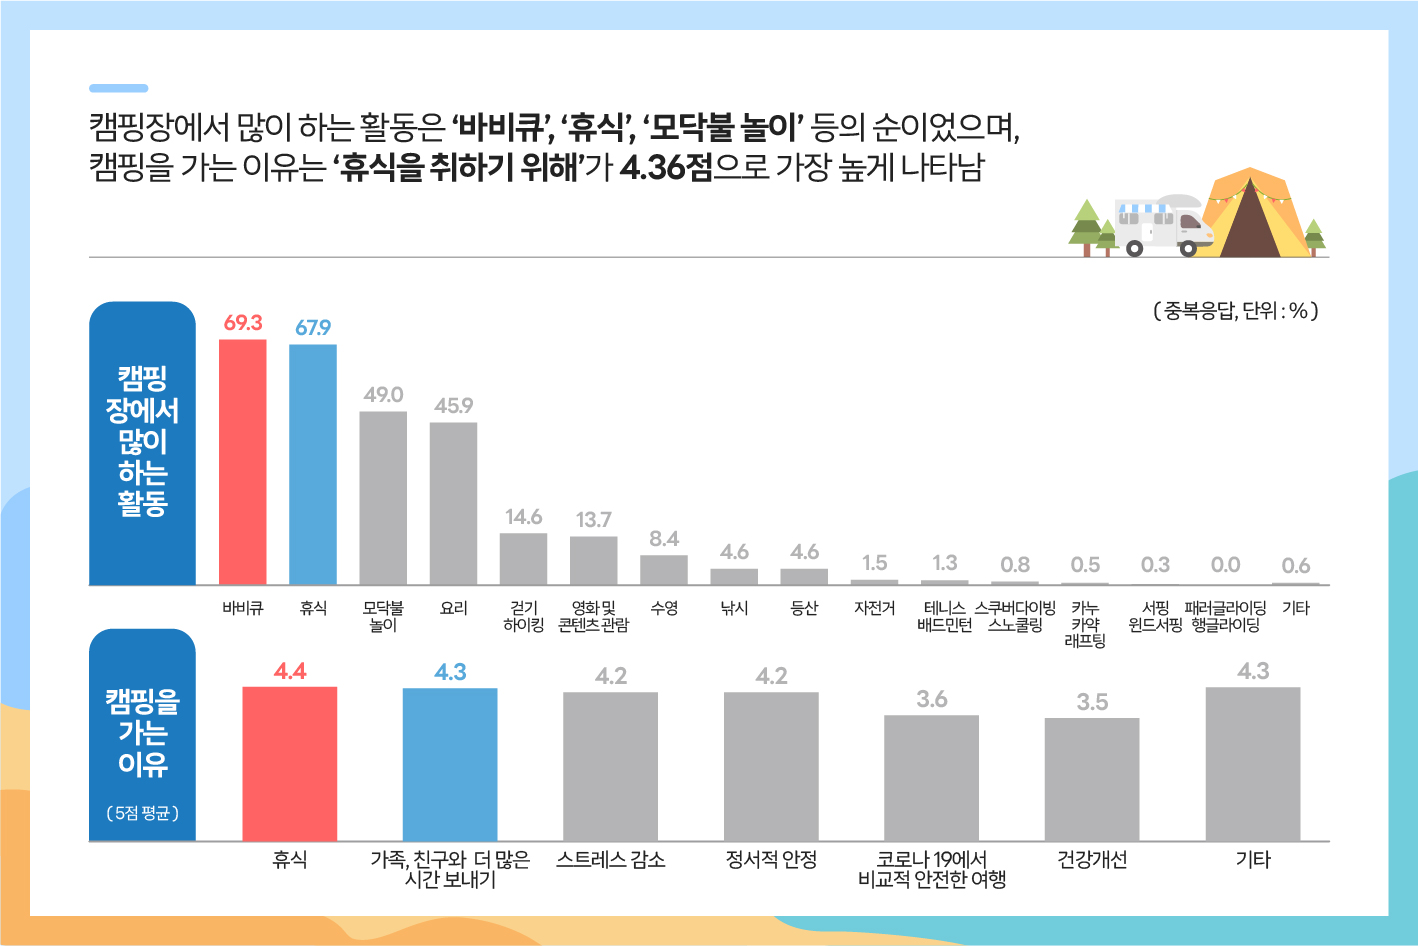

In [ ]:
accom_data = {
    '기초지자체': ['강진군', '고흥군', '곡성군', '광양시', '구례군', '나주시', '담양군', '목포시', '무안군', '보성군',
              '순천시', '신안군', '여수시', '영광군', '영암군', '완도군', '장성군', '장흥군', '진도군', '함평군',
              '해남군', '화순군'],
    '캠핑시설': [7, 20, 19, 15, 9, 6, 18, 1, 9, 11,
              10, 11, 25, 7, 9, 4, 23, 9, 2, 8,
              10, 13]}

accom_df = pd.DataFrame(accom_data)

df_1 = pd.merge(df_1, accom_df, on='기초지자체', how='left')
df_1.head()

,기초지자체,치유의숲,생태경관,템플스테이,피부미용업,한방병원,우수웰니스관광지,숙박시설,캠핑시설
0,강진군,0,0,2,7,2,0,39,7
1,고흥군,1,1,1,6,5,0,66,20
2,곡성군,1,0,1,5,2,0,23,19
3,광양시,1,1,0,25,12,0,107,15
4,구례군,0,2,3,1,3,0,65,9


- 지역별 방문자 수
https://datalab.visitkorea.or.kr/datalab/portal/loc/getAreaDataForm.do#
  - 근데 이건 총량 활용 권장 X로 써있어서..... 일단 사용X

### 관광지출액 결합

In [ ]:
df_2 = pd.read_csv('/content/drive/MyDrive/BDA/외부데이터-지역별 관광지출액/전남_관광지출액_집계.csv')
df_2.head()

,기초지자체,골프장,관광기념품,관광유원시설,관광총소비,기타레저,기타숙박,대형쇼핑몰,레저용품쇼핑,렌터카,면세점,문화서비스,수상운송,식음료,여행업,육상운송,캠핑장/펜션,콘도,호텔
0,강진군,3163330.0,137079.0,19525.0,14736586.0,112866.0,605281.0,2000.0,425992.0,1840.0,0.0,13966.0,0.0,10179466.0,5380.0,0.0,40127.0,0.0,29733.0
1,고흥군,100110.0,7182.0,7785.0,14179566.0,160988.0,895498.0,550093.0,1323891.0,1199.0,0.0,52219.0,820.0,10749595.0,577.0,0.0,32510.0,297099.0,0.0
2,곡성군,6545415.0,69223.0,79969.0,18357591.0,1664.0,142572.0,225001.0,19218.0,0.0,0.0,415097.0,0.0,10710827.0,128281.0,0.0,20221.0,102.0,0.0
3,광양시,1815937.0,21176.0,19067.0,72847336.0,593766.0,2868925.0,26954078.0,3621787.0,13208.0,0.0,477595.0,0.0,36428025.0,2107.0,660.0,31007.0,0.0,0.0
4,구례군,30385.0,47814.0,73.0,11612513.0,5736.0,465009.0,0.0,147364.0,21080.0,0.0,121892.0,0.0,10040651.0,0.0,27200.0,21128.0,293561.0,390619.0


In [ ]:
merged_df = pd.merge(df_1, df_2, on='기초지자체', how='outer')
merged_df

,기초지자체,치유의숲,생태경관,템플스테이,피부미용업,한방병원,우수웰니스관광지,숙박시설,캠핑시설,골프장,...,렌터카,면세점,문화서비스,수상운송,식음료,여행업,육상운송,캠핑장/펜션,콘도,호텔
0,강진군,0,0,2,7,2,0,39,7,3163330.0,...,1840.0,0.0,13966.0,0.0,10179466.0,5380.0,0.0,40127.0,0.0,29733.0
1,고흥군,1,1,1,6,5,0,66,20,100110.0,...,1199.0,0.0,52219.0,820.0,10749595.0,577.0,0.0,32510.0,297099.0,0.0
2,곡성군,1,0,1,5,2,0,23,19,6545415.0,...,0.0,0.0,415097.0,0.0,10710827.0,128281.0,0.0,20221.0,102.0,0.0
3,광양시,1,1,0,25,12,0,107,15,1815937.0,...,13208.0,0.0,477595.0,0.0,36428025.0,2107.0,660.0,31007.0,0.0,0.0
4,구례군,0,2,3,1,3,0,65,9,30385.0,...,21080.0,0.0,121892.0,0.0,10040651.0,0.0,27200.0,21128.0,293561.0,390619.0
5,나주시,1,0,0,39,16,0,59,6,13738863.0,...,27435.0,0.0,432310.0,0.0,33034161.0,30960.0,2909.0,3160.0,2039369.0,0.0
6,담양군,0,0,0,5,10,0,79,18,3760415.0,...,3606.0,0.0,667427.0,0.0,49290349.0,1008.0,2011.0,44369.0,0.0,0.0
7,목포시,0,0,0,131,43,0,306,1,1942277.0,...,63817.0,0.0,1183839.0,208196.0,82781507.0,112229.0,10529.0,220.0,0.0,629514.0
8,무안군,0,0,0,47,10,0,70,9,8427113.0,...,130.0,575685.0,76070.0,0.0,29153603.0,170.0,0.0,60682.0,2829.0,0.0
9,보성군,0,0,1,5,6,1,44,11,2231554.0,...,0.0,0.0,192558.0,0.0,13365234.0,101264.0,0.0,9690.0,411491.0,0.0


In [ ]:
merged_df.to_csv('/content/drive/MyDrive/BDA/EFA용_병합데이터.csv', index=False, encoding='utf-8-sig')

# 가중치 산출(EFA) + 관광지수

In [46]:
import pandas as pd
data_all = pd.read_csv('/content/drive/MyDrive/BDA/EFA용_병합데이터.csv')

In [47]:
data_all.columns

Index(['기초지자체', '치유의숲', '생태경관', '템플스테이', '피부미용업', '한방병원',
       '우수웰니스관광지', '숙박시설', '캠핑시설', '골프장', '관광기념품', '관광유원시설', '관광총소비', '기타레저',
       '기타숙박', '대형쇼핑몰', '레저용품쇼핑', '렌터카', '면세점', '문화서비스', '수상운송', '식음료', '여행업',
       '육상운송', '캠핑장/펜션', '콘도', '호텔'],
      dtype='object')

In [48]:
# 컬럼명 인코딩 오류 수정: 템플스테이, 피부미용업의 컬럼명이 깨져 있어서 ['템플'] → .rename()으로 수정 필요

# 깨진 컬럼명을 올바르게 복구
data_all = data_all.rename(columns={
    '템플스테이': '템플스테이',
    '피부미용업': '피부미용업'
})

In [49]:
data_all['템플스테이']

,템플스테이
0,2
1,1
2,1
3,0
4,3
5,0
6,0
7,0
8,0
9,1


In [50]:
# 1. 목적에 맞는 변수만 선택
selected_cols = [
      '치유의숲', '생태경관', '템플스테이','피부미용업', '한방병원',
      '우수웰니스관광지', '숙박시설', '캠핑시설','관광기념품', '관광유원시설', '관광총소비','문화서비스', '식음료', '여행업', '호텔']

data = data_all[selected_cols]

# 2. 표준화
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# 3. 다시 데이터프레임으로 감싸기
import pandas as pd
data_scaled = pd.DataFrame(data_scaled, columns=data.columns)

## 2. KMO & Bartlett’s Test로 요인분석 적합성 확인

In [51]:
# Bartlett 검정
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

chi_square_value, p_value = calculate_bartlett_sphericity(data_scaled)
chi_square_value, p_value

(np.float64(380.24334292644835), np.float64(7.758778872495689e-33))

p-value가 거의 0에 가까워야 함. 검정이 통계적으로 유의하다는 것을 의미하며, 이는 변수들 간 상관관계 존재 → 요인분석을 진행할 수 있음을 의미.

- chi_square_value: 199.93768877703512 → 값이 클수록 좋음 (상관관계 있음)

- p-value: 2.03e-21 → 0에 매우 가까움 → 유의미한 상관관계 존재

따라서 Bartlett 검정 통과 → 요인분석 가능함

In [52]:
# KMO(Kaiser-Meyer-Olkin) 검사
from factor_analyzer.factor_analyzer import calculate_kmo

kmo_all, kmo_model = calculate_kmo(data_scaled)
kmo_model

np.float64(0.6627757530265039)

0.6이 넘어야 함. 이는 요인분석을 진행할 수 있음을 의미
- 변수 간에 요인 구조가 존재할 가능성이 있으므로 다음 단계로 진행 가능!!

## 3. 요인 수 결정 (scree plot 또는 eigenvalue ≥ 1 기준)

In [53]:
from factor_analyzer import FactorAnalyzer

# 요인분석 모델 선언 (요인 수는 일단 아무 숫자, 예: 10)
fa = FactorAnalyzer(n_factors=data.shape[1], rotation=None)
fa.fit(data_scaled)

# 고유값 추출
ev, v = fa.get_eigenvalues()

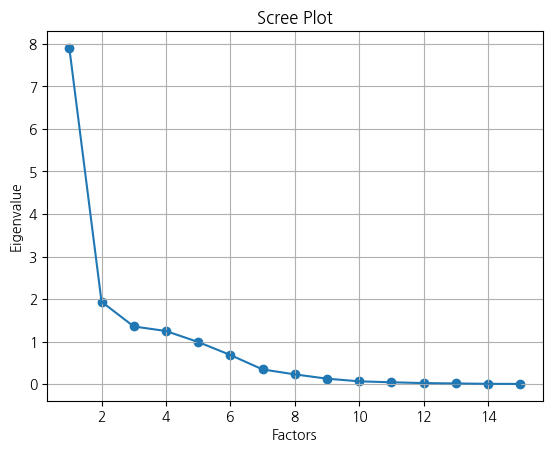

In [54]:
# Scree plot 생성
import matplotlib.pyplot as plt
plt.scatter(range(1, data.shape[1]+1), ev)
plt.plot(range(1, data.shape[1]+1), ev)
plt.title('Scree Plot')
plt.xlabel('Factors')
plt.ylabel('Eigenvalue')
plt.grid()
plt.show()

In [55]:
# 고유값 출력
for i, val in enumerate(ev, start=1):
    print(f"Factor {i}: Eigenvalue = {val:.4f}")

Factor 1: Eigenvalue = 7.9017
Factor 2: Eigenvalue = 1.9380
Factor 3: Eigenvalue = 1.3569
Factor 4: Eigenvalue = 1.2492
Factor 5: Eigenvalue = 0.9917
Factor 6: Eigenvalue = 0.6856
Factor 7: Eigenvalue = 0.3470
Factor 8: Eigenvalue = 0.2308
Factor 9: Eigenvalue = 0.1296
Factor 10: Eigenvalue = 0.0670
Factor 11: Eigenvalue = 0.0449
Factor 12: Eigenvalue = 0.0257
Factor 13: Eigenvalue = 0.0171
Factor 14: Eigenvalue = 0.0086
Factor 15: Eigenvalue = 0.0062


1보다 큰 고유값의 개수를 요인 수로 간주함.

그래프 해석:
- 1번 요인: 고유값 거의 5
- 2번 요인: 고유값 약 1.7
- 3번 요인: 고유값 약 1.2
- 4번 요인: 고유값 약 1.0 (경계선)
- 5번 요인 이후: 고유값이 1보다 작음

결론:
고유값이 1 이상인 요인은 4개

따라서 요인 수는 4개로 결정하는 것이 적절.

## 4. 요인 추출 (보통 최소제곱법이나 주성분분석 사용) & 5. 요인 회전 (varimax 회전: 해석 용이, orthogonal) & 6. 요인 해석 및 변수군 구성



In [56]:
## 3트

# 요인분석
fa = FactorAnalyzer(n_factors=4, method= 'principal', rotation='equamax')
fa.fit(data_scaled)

# 요인 적재량 확인
loadings = pd.DataFrame(fa.loadings_, index=data.columns)
print(loadings)

# 변수군 구성 (적재량 0.4 이상 변수별 요인 배정)
threshold = 0.4
max_loadings = loadings.abs().idxmax(axis=1)
factor_vars = {}
for factor in loadings.columns:
    vars_in_factor = loadings.index[(loadings[factor].abs() >= threshold) & (max_loadings == factor)].tolist()
    factor_vars[factor] = vars_in_factor

for factor, variables in factor_vars.items():
    print(f"\n{factor} 변수군:")
    print(variables)

                 0         1         2         3
치유의숲     -0.194488  0.057512  0.052687  0.928087
생태경관     -0.156456 -0.147233  0.772397  0.050979
템플스테이     0.011768 -0.034645  0.555330 -0.019136
피부미용업     0.498127  0.832824 -0.042752 -0.100754
한방병원      0.650260  0.720081 -0.019336  0.039714
우수웰니스관광지 -0.129796 -0.152674 -0.644697 -0.066808
숙박시설      0.959780  0.158259  0.046646 -0.085272
캠핑시설      0.395306 -0.490023 -0.012149  0.689026
관광기념품     0.929129 -0.267122 -0.052270 -0.006823
관광유원시설    0.957500 -0.026024 -0.014296 -0.049418
관광총소비     0.871716  0.436653 -0.013514  0.062627
문화서비스     0.984498  0.039011 -0.018378  0.056664
식음료       0.881432  0.417415 -0.020800  0.048801
여행업       0.881379 -0.060041 -0.078389  0.061857
호텔        0.885805 -0.209717  0.124884 -0.160435

0 변수군:
['숙박시설', '관광기념품', '관광유원시설', '관광총소비', '문화서비스', '식음료', '여행업', '호텔']

1 변수군:
['피부미용업', '한방병원']

2 변수군:
['생태경관', '템플스테이', '우수웰니스관광지']

3 변수군:
['치유의숲', '캠핑시설']


* rotation(요인회전) : ['varimax', 'oblimax', 'quartimax', 'equamax', 'geomin_ort', 'promax', 'oblimin', 'quartimin', 'geomin_obl', None]
* method(요인추출) : ['ml', 'mle', 'uls', 'minres', 'principal']

하나씩 넣어가며 바꿔가며(rotation / method) 요인이 잘 묶이는 걸 선택하기!!

치유-생태 / 템플스테이-숙박

이런 식으로 묶이면 좋을 거 같은데.. 일단 처음 변수문제 해결 후 더 돌려보기. 일단 principal/varimax 조합 사용

## 7. 요인점수 계산

In [57]:
factor_scores = fa.transform(data_scaled)
factor_scores_df = pd.DataFrame(factor_scores, columns=[f'Factor_{i+1}' for i in range(factor_scores.shape[1])])
factor_scores_df.head()

,Factor_1,Factor_2,Factor_3,Factor_4
0,-0.421627,-0.399838,0.455660,-0.888717
1,-0.441952,-0.398571,1.052764,1.602198
2,-0.102127,-0.673827,-0.188050,1.604474
3,-0.147673,0.614247,0.655488,1.519532
4,-0.324881,-0.783504,3.199128,-0.935151


In [58]:
factor_scores_df

,Factor_1,Factor_2,Factor_3,Factor_4
0,-0.421627,-0.399838,0.455660,-0.888717
1,-0.441952,-0.398571,1.052764,1.602198
2,-0.102127,-0.673827,-0.188050,1.604474
3,-0.147673,0.614247,0.655488,1.519532
4,-0.324881,-0.783504,3.199128,-0.935151
5,-0.207878,1.122298,-0.433250,0.895005
6,0.186320,-0.296193,-0.524936,0.219369
7,1.255578,2.954585,-0.246091,-0.816431
8,-0.266602,0.789066,-0.417137,-0.414594
9,-0.097390,-0.754804,-0.795590,-0.517450


---

## 8. 웰니스 관광지수 만들기

* 1. 요인적재량이 높은 항목들을 묶어 2~3개 요인(자연/서비스/힐링 등) 설정
* 2. 요인 점수 추출 → 각 사람(또는 지역)의 요인 점수 계산
* 3. 가중 평균 or 단순 평균으로 지수화


In [59]:
ev # 변수 군집화 전이라 10개 나옴, 4개만 나와야 함

array([7.90171800e+00, 1.93800858e+00, 1.35685696e+00, 1.24920455e+00,
       9.91713308e-01, 6.85636436e-01, 3.46955193e-01, 2.30820613e-01,
       1.29592887e-01, 6.70055215e-02, 4.48610913e-02, 2.56727577e-02,
       1.71499640e-02, 8.59704230e-03, 6.20709364e-03])

In [60]:
# 요인 수를 4개로 지정하여 다시 분석
from factor_analyzer import FactorAnalyzer

fa = FactorAnalyzer(n_factors=5, rotation='equamax')  # rotation은 선택했던 방식 사용
fa.fit(data_scaled)  # 최종 변수들로 구성된 스케일링 데이터 사용

# 고유값 추출
ev, _ = fa.get_eigenvalues()
ev = ev[:5]  # 앞의 4개 요인에 대한 고유값만 사용

In [61]:
ev

array([7.901718  , 1.93800858, 1.35685696, 1.24920455, 0.99171331])

In [62]:
# 고유값 기반 가중치 계산
weights = ev / ev.sum()

# 요인 점수 가져오기
factor_scores = fa.transform(data_scaled)
factor_scores_df = pd.DataFrame(
    factor_scores,
    columns=[f'Factor_{i+1}' for i in range(factor_scores.shape[1])]
)

# 웰니스 관광지수 계산
factor_scores_df['웰니스관광지수'] = sum(
    factor_scores_df[f'Factor_{i+1}'] * weights[i] for i in range(4)
)

In [63]:
# 결과 확인
factor_scores_df.head()

,Factor_1,Factor_2,Factor_3,Factor_4,Factor_5,웰니스관광지수
0,-0.289063,-0.814618,-0.740485,1.103694,-0.983944,-0.259634
1,-0.474689,-0.174675,1.535311,0.138152,-0.112338,-0.136454
2,-0.457468,0.116110,2.340376,-0.033518,0.562269,-0.019057
3,-0.207998,0.823341,0.592986,-1.096222,2.190951,-0.045597
4,-0.305489,-0.811491,-0.540705,2.114562,1.805204,-0.154694


웰니스관광지수: 표준화된 데이터를 바탕으로 도출되므로, 평균이 0이고 음/양수가 섞여 나옴

음수: 평균보다 해당 요인의 특성이 약한 지역

양수: 평균보다 해당 요인의 특성이 강한 지역

In [64]:
# 음수 없이 지수를 표현: 가중합 후 지수를 0~1 사이로 정규화
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
factor_scores_df['웰니스지수_정규화'] = scaler.fit_transform(factor_scores_df[['웰니스관광지수']])

In [65]:
# 결과 확인
factor_scores_df.head()

,Factor_1,Factor_2,Factor_3,Factor_4,Factor_5,웰니스관광지수,웰니스지수_정규화
0,-0.289063,-0.814618,-0.740485,1.103694,-0.983944,-0.259634,0.101122
1,-0.474689,-0.174675,1.535311,0.138152,-0.112338,-0.136454,0.144979
2,-0.457468,0.116110,2.340376,-0.033518,0.562269,-0.019057,0.186778
3,-0.207998,0.823341,0.592986,-1.096222,2.190951,-0.045597,0.177328
4,-0.305489,-0.811491,-0.540705,2.114562,1.805204,-0.154694,0.138485


In [66]:
factor_scores_df['기초지자체'] = data_all['기초지자체'].values
factor_scores_df[['기초지자체', '웰니스지수_정규화']].head()

,기초지자체,웰니스지수_정규화
0,강진군,0.101122
1,고흥군,0.144979
2,곡성군,0.186778
3,광양시,0.177328
4,구례군,0.138485


In [67]:
factor_scores_df2 = factor_scores_df.sort_values(by='웰니스지수_정규화', ascending=False)

In [68]:
factor_scores_df2

,Factor_1,Factor_2,Factor_3,Factor_4,Factor_5,웰니스관광지수,웰니스지수_정규화,기초지자체
12,4.114483,-1.567501,0.656296,0.057589,-0.064575,2.265011,1.000000,여수시
10,0.724282,2.388594,0.039879,2.308448,-1.834909,0.989025,0.545696,순천시
7,1.339545,2.604973,-1.359176,-1.091158,1.281259,0.924717,0.522800,목포시
6,0.137695,0.012274,0.972192,-1.001009,0.039065,0.087849,0.224841,담양군
21,-0.549336,1.121702,1.022626,1.010965,0.933395,0.035991,0.206377,화순군
2,-0.457468,0.116110,2.340376,-0.033518,0.562269,-0.019057,0.186778,곡성군
3,-0.207998,0.823341,0.592986,-1.096222,2.190951,-0.045597,0.177328,광양시
16,-0.432189,-0.178359,1.953221,-0.013183,-0.409257,-0.083864,0.163704,장성군
20,-0.257913,-0.214445,0.009212,1.035491,0.114299,-0.085396,0.163158,해남군
8,-0.293316,0.865319,0.248834,-1.037591,0.458007,-0.119013,0.151189,무안군


In [69]:
factor_scores_df2.to_csv('/content/drive/MyDrive/BDA/웰니스지수데이터_최종.csv', index=False, encoding='utf-8-sig')